---
title: "Step 2.8. Additional SENDA evaluation: post-discharge mortality in the homelessness programme"
description: |
  This notebook preserves the original adult homelessness-programme cohort,
  overlap exclusion, discharge time origin and mortality follow-up cutoff.
  The accepted SHAP mortality model e and the development-only missRanger
  imputers are reused without fitting to this additional cohort. All 39
  imputer inputs are audited before frozen application. Missing predictors
  without a fitted development imputation model stop execution explicitly.
  Historical complete-case results are reproduced as controls, separately
  from the new cohort and new frozen-model predictions. Horizon-specific
  discrimination, classical integrated Brier score and grouped KM calibration
  use the original engines. Patient bootstrap uncertainty keeps predictions
  fixed and re-estimates censoring weights within each of 1000 resamples.

date: last-modified
author: "Andres Gonzalez Santa Cruz"
bibliography: [_lit/refs.bib]
csl: "_lit/american-medical-association.csl"
toc: true
toc-location: left
toc-float: true
format:
  html:
    css: [_lib/styles.scss, _lib/prediction_metrics_compact.css]
    code-fold: true
    embed-resources: true
    theme:
      - journal
    fig-cap-location: top
    toc: true
    toc-location: left
execute:
  error: false
  echo: true
  warning: true
  message: true
  freeze: auto
editor: source
execute-dir: project
lightbox: auto
---


## Current stage and decisions
The original Table 4 used 605 complete cases and 71 deaths. The original eligibility rules identify 618 people and 72 deaths. The investigator approved a primary analysis of 613 people with a recorded index discharge reason, keeping all 72 deaths, and a separate 618-person sensitivity for uncertain physical status and missing discharge reasons.
The approved physical rule matches development: any recorded positive physical diagnosis takes precedence over a status label in another field. Under-study-only records remain without confirmed comorbidity; people are not excluded for that status.
Housing tenure is absent throughout C3 and must be inferred from development donors. Those donor patterns may not transfer to this programme. Poverty is available. The investigator confirmed retention of its development source-year definition; the upstream issue remains a limitation and its correction is outside this closure.
```{mermaid}
flowchart TD
 A[Original C3 records] --> B[Original overlap, age and discharge rules]
 B --> C[First qualifying episode: 648]
 C --> D[Remove 28 not alive at discharge]
 D --> E[Remove 2 early deaths after administrative discharge]
 E --> F[Eligible: 618 people, 72 deaths]
 F --> G[Approved primary: 613 people with recorded discharge]
 F --> H[Requested sensitivity: all 618 people]
 G --> I[Approved: retain trained poverty definition]
 H --> I
 I --> J[Five development imputers and frozen Cox e fits]
 J --> K[C / integrated IBS / calibration / interval widths]
 K --> L[Table 4 comparison and explicit limitations]
```

In [1]:
#| label: c3-setup
#| message: false
.t0 <- proc.time()
# Resolve every input and output from the shared configuration.
locale_target <- if(.Platform$OS.type=="windows") "English_United States.utf8" else "C.UTF-8"
locale_active <- Sys.setlocale("LC_CTYPE",locale_target)
if(!nzchar(locale_active)) stop("Required UTF-8 locale is unavailable: ",locale_target)
RNGkind("Mersenne-Twister","Inversion","Rejection")
root <- normalizePath(getwd(),winslash="/",mustWork=TRUE)
while(!file.exists(file.path(root,"config.yml"))) {
  parent <- dirname(root)
  if(identical(parent,root)) stop("config.yml was not found above the working directory.")
  root <- parent
}
cfg <- yaml::read_yaml(file.path(root,"config.yml"))
config <- cfg
resolve <- function(p) {
  stopifnot(is.character(p),length(p)==1L,nzchar(p))
  if(grepl("^(?:[A-Za-z]:|/)",p,perl=TRUE)) p else file.path(root,p)
}
# Verify the same frozen R libraries as notebooks 00 and 09 before scientific namespaces load.
.libPaths(c(vapply(cfg$runtime$r_libraries,resolve,character(1)),.libPaths()))
lock <- jsonlite::read_json(resolve(cfg$runtime$r_lock),simplifyVector=FALSE)
stopifnot(as.character(getRversion())==lock$R$Version)
required_packages <- c("yaml","jsonlite","digest","ps","missRanger","ranger","survival","pec","dplyr","future","future.apply","ggplot2","htmltools","IRdisplay","knitr","readxl","lubridate","stringi","stringr")
for(package in required_packages) {
  stopifnot(requireNamespace(package,quietly=TRUE))
  expected <- lock$Packages[[package]]$Version
  if(is.null(expected)||utils::packageVersion(package)!=base::package_version(expected)) stop("Package version differs from lock: ",package)
}
Surv <- survival::Surv
strata <- survival::strata
required_sources <- c("homeless_inputs","homeless_pndr","homeless_poverty_2011","homeless_poverty_2013","homeless_poverty_2020","homeless_historical","holdout_notebook","holdout_frozen_models","clean_preparation_cache","frozen_imputers","homeless_historical_ibs")
missing_sources <- setdiff(required_sources,names(cfg$sources))
if(length(missing_sources)) stop("Configuration entries required: ",paste(missing_sources,collapse=", "))
Sys.setenv(OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1",MKL_NUM_THREADS="1",VECLIB_MAXIMUM_THREADS="1")
future::plan(future::sequential)
set.seed(as.integer(cfg$imputation$seed))
written <- character()
execution_started <- Sys.time()
run_date <- format(Sys.Date(),"%Y-%m-%d")
HORIZONS <- c(6,12,36,60)
GRID <- seq(0.25,60,by=0.25)
B_BOOT <- 1000L
BOOT_SEED <- 2125L
show_table <- function(x,caption) {
  widget <- knitr::kable(x,format="html",caption=caption,row.names=FALSE,digits=6)
  display <- htmltools::browsable(htmltools::tags$div(role="region",tabindex=0,`aria-label`=caption,style="max-height:520px;overflow:auto;max-width:100%;",htmltools::HTML(widget)))
  IRdisplay::display_html(as.character(display))
  invisible(display)
}
prep <- readRDS(resolve(cfg$sources$clean_preparation_cache))
stopifnot(nrow(prep$development)==70521L,ncol(prep$development)==39L)
show_table(data.frame(Notebook="11_homeless_progr_death_int_val.ipynb",Language="R",Kernel="ir",Environment="r-main / R 4.4.1",Threads=1L),"Execution environment")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Notebook,Language,Kernel,Environment,Threads
11_homeless_progr_death_int_val.ipynb,R,ir,r-main / R 4.4.1,1


Elapsed: 0.037 minutes


In [2]:
#| label: c3-original-cohort-builder
#| message: false
.t0 <- proc.time()
# Preserve the original builder and recoders verbatim; the C3 input directory is explicit.
.evd_norm <- function(x) stringr::str_squish(stringr::str_to_lower(
  stringi::stri_trans_general(as.character(x), "Latin-ASCII")))
.evd_sex <- function(x) {
  v <- .evd_norm(x)
  dplyr::case_when(v %in% c("mujer", "femenino") ~ "woman",
                   v %in% c("hombre", "masculino") ~ "man",
                   TRUE ~ NA_character_)
}
# primary substance -> {cocaine paste, cocaine powder, alcohol, marijuana(ref), others}
.evd_primary_sub <- function(x) {
  v <- .evd_norm(x)
  dplyr::case_when(
    stringr::str_detect(v, "pasta\\s*base|pasta|\\bpaco\\b") ~ "cocaine paste",
    stringr::str_detect(v, "clorhidrato|cocaina|cocaina|cocaina|cocano|cocaina") ~ "cocaine powder",
    stringr::str_detect(v, "^alcohol$|\\balcohol\\b") ~ "alcohol",
    stringr::str_detect(v, "marihu|marij|cannab") ~ "marijuana",
    is.na(x) ~ NA_character_,
    TRUE ~ "others")
}
# substance of onset -> same families (only first_sub_used_alcohol is in the model)
.evd_first_sub <- function(x) {
  v <- .evd_norm(x)
  dplyr::case_when(
    stringr::str_detect(v, "^alcohol$|\\balcohol\\b") ~ "alcohol",
    stringr::str_detect(v, "marihu|marij|cannab") ~ "marijuana",
    stringr::str_detect(v, "pasta\\s*base|pasta|\\bpaco\\b") ~ "cocaine paste",
    stringr::str_detect(v, "clorhidrato|cocaina|cocano") ~ "cocaine powder",
    is.na(x) ~ NA_character_,
    TRUE ~ "others")
}
# frequency -> {1.<=1 day/wk(ref), 2.2-6 days/wk, 3.Daily}; en-dash U+2013 preserved
.evd_freq <- function(x) {
  v <- .evd_norm(x)
  dplyr::case_when(
    stringr::str_detect(v, "todos los dias|diario|diaria") ~ "3.Daily",
    stringr::str_detect(v, "2-3 dias|4-6 dias|2 a 3|4 a 6") ~ "2.2\u20136 days/wk",
    stringr::str_detect(v, "1 dia|1 dias|menos de 1|no consumio") ~ "1.\u22641 day/wk",
    stringr::str_detect(v, "desconocida|desconocido") ~ NA_character_,
    is.na(x) ~ NA_character_,
    TRUE ~ NA_character_)
}
# occupational condition -> {employed(ref), unemployed, inactive} (corr24 logic:
# working -> employed; cesante / first-time job seeker -> unemployed; the rest,
# incl. "sin actividad" / students / homemakers / pensioners -> inactive)
.evd_occupation <- function(x) {
  v <- .evd_norm(x)
  dplyr::case_when(
    is.na(x) ~ NA_character_,
    stringr::str_detect(v, "trabajando") ~ "employed",
    v %in% c("cesante", "buscando trabajo por primera vez") ~ "unemployed",
    TRUE ~ "inactive")
}
# discharge-evaluation domains -> {logro alto(ref), logro intermedio, logro minimo}
.evd_eva <- function(x) {
  v <- .evd_norm(x)
  dplyr::case_when(
    stringr::str_detect(v, "logro alto|alto") ~ "logro alto",
    stringr::str_detect(v, "intermedio") ~ "logro intermedio",
    stringr::str_detect(v, "minimo|nulo") ~ "logro minimo",
    TRUE ~ NA_character_)
}
# cohabitation status -> {alone(ref), with couple/children, family of origin, others}.
# Same category scheme/logic as extval_01_build_cohort.R's cohabitation recoder
# (traced to prediction1.qmd:1682-1715), extended for the "/a"/"/as" gender-suffix
# raw variants observed in the SENDA C3/C5 con_quien_vive field (e.g. "solo/a",
# "unicamente con hijos/as") and for "con el padre (solo)" (C5), which was missing
# from the original regex even though its exact counterpart "con la madre (sola)"
# was already mapped to Family of origin.
.evd_cohabitation <- function(x) {
  cqv <- .evd_norm(x)
  joel5 <- dplyr::case_when(
    is.na(x) ~ NA_character_,
    stringr::str_detect(cqv, "^solo(/a)?$") ~ "Alone",
    stringr::str_detect(cqv, "^unicamente con (la )?pareja( e hijos(/as)?)?$") |
      stringr::str_detect(cqv, "^unicamente con pareja$") |
      stringr::str_detect(cqv, "^unicamente con hijos(/as)?$") ~ "Couple/children only",
    stringr::str_detect(cqv, "(pareja|hijos).*(padres|familia de origen)") |
      stringr::str_detect(cqv, "^con la pareja,? hijos y padres") ~ "Couple/children + origin",
    stringr::str_detect(cqv, "^unicamente con padres|^con padres|familia de origen$") |
      stringr::str_detect(cqv, "^con la madre \\(sola\\)$") |
      stringr::str_detect(cqv, "^con el padre \\(solo\\)$") |
      stringr::str_detect(cqv, "^con abuelos$") |
      stringr::str_detect(cqv, "^con hermanos$") ~ "Family of origin",
    stringr::str_detect(cqv, "con amigos|otro no pariente|otro pariente|^otros$") ~ "Others",
    TRUE ~ "Others")
  dplyr::case_when(
    joel5 == "Alone" ~ "alone",
    joel5 %in% c("Couple/children only", "Couple/children + origin") ~ "with couple/children",
    joel5 == "Family of origin" ~ "family of origin",
    is.na(joel5) ~ NA_character_,
    TRUE ~ "others")
}
# any physical comorbidity: non-empty, non-"none"/"in study" physical diagnosis
.evd_any_phys <- function(...) {
  cols <- list(...)
  pf <- do.call(paste, c(lapply(cols, function(z) ifelse(is.na(z), "", as.character(z))), sep = " ::: "))
  pf <- .evd_norm(pf)
  out <- nzchar(pf) &
    !stringr::str_detect(pf, "sin (diagnostico|patologia|trastorno)|no (presenta|refiere|aplica)|ninguno|en estudio")
  # rows that were entirely missing -> NA
  allmiss <- Reduce(`&`, lapply(cols, function(z) is.na(z) | !nzchar(trimws(as.character(z)))))
  out[allmiss] <- NA
  out
}
# ---- per-convenio raw column maps --------------------------------------------
.evd_colmap <- list(
  C3 = list(
    id = "HASH_KEY", age = "edad", sex = "sexo",
    primary_sub = "sustancia_principal", first_sub = "sustancia_de_inicio",
    freq = "frecuencia_de_consumo_sustancia_principal",
    occupation = "condicion_ocupacional",
    eva_ocupacion = "evaluacion_al_egreso_respecto_sit_ocup",
    eva_fisica = "evaluacion_al_egreso_respecto_salud_fisica",
    cohab = "con_quien_vive",
    phys = c("diagnostico_trs_fisico", "diagnostico_trs_fisico2", "diagnostico_trs_fisico3"),
    adm = "fecha_ingreso_a_tratamiento", disch = "fecha_egreso_de_tratamiento",
    # Discharge reason. These two columns were always present in the extract but were not mapped,
    # which is why earlier notes claimed the convenio files had no discharge reason at all.
    disch_reason = "motivo_de_egreso", disch_admin_reason = "motivodeegreso_alta_administra",
    plan = NA_character_),                          # no plan column -> fixed pg-pr
  C5 = list(
    id = "HASH_KEY", age = "edad", sex = "sexo",
    primary_sub = "sustancia_principal", first_sub = "sustancia_inicial",
    freq = "frecuencia_consumo",
    occupation = "estado_laboral",
    eva_ocupacion = "evaluacion_al_egreso_respecto_a_situacion_ocupacional",
    eva_fisica = "evaluacion_al_egreso_respecto_salud_fisica",
    cohab = "con_quien_vive",
    phys = c("diagnostico_trs_fisico"),
    adm = "fecha_ingreso_a_tratamiento", disch = "fecha_egreso_de_tratamiento",
    disch_reason = "motivo_de_egreso", disch_admin_reason = "motivodeegreso_alta_administra",
    plan = "tipo_de_plan")
)
# adolescent plan codes (C5) -> development modality
.evd_plan_c5 <- function(x) {
  v <- .evd_norm(x)
  dplyr::case_when(
    stringr::str_detect(v, "^pai") ~ "pg-pai",   # outpatient intensive
    stringr::str_detect(v, "^pr|^ml-pr|^ml pr") ~ "pg-pr",  # residential
    is.na(x) ~ "pg-pr",
    TRUE ~ "pg-pr")
}
build_extval_death_cohort <- function(which = c("C3", "C5"),
                                      censor = "2020-12-31",
                                      age_lo = 18, age_hi = 64,
                                      alive_at_discharge = TRUE,
                                      precaution_months = 0.23,
                                      precaution_scope = c("administrative", "any", "none"),
                                      inputs_dir = NULL, verbose = TRUE) {
  which <- match.arg(which)
  precaution_scope <- match.arg(precaution_scope)
  .msg <- function(...) if (verbose) { cat(...); flush.console() }
  if (is.null(inputs_dir)) inputs_dir <- file.path(project_root, "data/20241015_out/_val_inputs")
  cm <- .evd_colmap[[which]]
  src <- file.path(inputs_dir, sprintf("extval_CONS_%s_25_df.rds", which))
  stopifnot(file.exists(src))
  raw <- as.data.frame(readRDS(src), stringsAsFactors = FALSE)
  dev_hash      <- readRDS(file.path(inputs_dir, "extval_dev_hash.rds"))
  death_by_hash <- as.data.frame(readRDS(file.path(inputs_dir, "extval_death_by_hash.rds")))
  .censor <- as.Date(censor)
  n0_rows <- nrow(raw); n0_pat <- dplyr::n_distinct(raw[[cm$id]])
  .msg(sprintf("[%s] raw: rows=%s patients=%s\n", which,
               format(n0_rows, big.mark = ","), format(n0_pat, big.mark = ",")))
  d <- data.frame(hash_key = as.character(raw[[cm$id]]), stringsAsFactors = FALSE)
  d$adm_age_rec3 <- suppressWarnings(as.numeric(raw[[cm$age]]))
  d$.adm   <- suppressWarnings(as.Date(raw[[cm$adm]],   format = "%d/%m/%Y"))
  d$.disch <- suppressWarnings(as.Date(raw[[cm$disch]], format = "%d/%m/%Y"))
  d$sex_rec           <- .evd_sex(raw[[cm$sex]])
  d$primary_sub_mod   <- .evd_primary_sub(raw[[cm$primary_sub]])
  d$first_sub_used    <- .evd_first_sub(raw[[cm$first_sub]])
  d$prim_sub_freq_rec <- .evd_freq(raw[[cm$freq]])
  d$occupation_condition_corr24 <- .evd_occupation(raw[[cm$occupation]])
  d$eva_ocupacion     <- .evd_eva(raw[[cm$eva_ocupacion]])
  d$eva_fisica        <- .evd_eva(raw[[cm$eva_fisica]])
  d$cohabitation      <- .evd_cohabitation(raw[[cm$cohab]])
  d$any_phys_dx       <- do.call(.evd_any_phys, lapply(cm$phys, function(cc) raw[[cc]]))
  d$plan_type_corr <- if (is.na(cm$plan)) "pg-pr" else .evd_plan_c5(raw[[cm$plan]])
  # Discharge reason, carried through so the alive-at-origin rules below can be reason-based rather
  # than date-based only. Not a model covariate: the frozen death model does not use it.
  d$disch_reason <- .evd_norm(raw[[cm$disch_reason]])
  d$disch_admin_reason <- .evd_norm(raw[[cm$disch_admin_reason]])
  # 1) exclude development patients (convenio 1 + women's plans = original sample)
  in_dev <- d$hash_key %in% dev_hash
  d1 <- d[!in_dev, , drop = FALSE]
  .msg(sprintf("1. exclude development-cohort patients: removed %s rows; %s remain\n",
               format(sum(in_dev), big.mark = ","), format(nrow(d1), big.mark = ",")))
  # 2) adults in model scope + valid admission/discharge in death-ascertainment window
  d2 <- d1[!is.na(d1$adm_age_rec3) & d1$adm_age_rec3 >= age_lo & d1$adm_age_rec3 <= age_hi, , drop = FALSE]
  n_adult <- nrow(d2)
  d2 <- d2[!is.na(d2$.disch) & d2$.disch <= .censor, , drop = FALSE]
  n_disch_ok <- nrow(d2)
  .msg(sprintf("2. adults %d-%d: %s ; with discharge on/before %s: %s\n",
               age_lo, age_hi, format(n_adult, big.mark = ","),
               format(.censor), format(n_disch_ok, big.mark = ",")))
  # 3) first qualifying episode per patient (discharge clock anchor)
  d3 <- d2 |>
    dplyr::arrange(hash_key, .adm, .disch) |>
    dplyr::distinct(hash_key, .keep_all = TRUE)
  .msg(sprintf("3. first episode per patient: %s\n", format(nrow(d3), big.mark = ",")))
  # 4) death outcome from the registry (clock = discharge), censor 2020-12-31
  d3 <- dplyr::left_join(d3, death_by_hash, by = c("hash_key" = "hashkey"))
  d3$death_event <- as.integer(!is.na(d3$def_date) & d3$def_date <= .censor &
                                 d3$def_date >= d3$.disch)
  end_date <- dplyr::if_else(d3$death_event == 1L, d3$def_date, .censor)
  d3$death_time_from_disch_m <- as.numeric(
    lubridate::time_length(lubridate::interval(d3$.disch, end_date), "months"))
  d3$death_time_from_disch_m <- pmax(d3$death_time_from_disch_m, 0)
  # 5) post-discharge definition: the cohort must be ALIVE at the time origin, and deaths falling
  #    inside a short precautionary window after an administrative discharge are removed because
  #    such a discharge is plausibly a consequence of the terminal event rather than a prognosis
  #    made from a stable state. Both rules are counted before being applied so the flow table
  #    shows what was removed and why, and both can be switched off to reproduce the historical
  #    code literally as an adversarial arm.
  # WHY THIS IS NEEDED: death_event above requires def_date >= .disch. A patient whose registered
  # death date PRECEDES the discharge date therefore fails that test and is carried as a CENSORED
  # SURVIVOR, that is, a dead patient counted as alive. Convenio 3 has 20 such patients against 82
  # deaths, so the misclassification is not a rare edge case.
  .not_alive <- !is.na(d3$def_date) & !is.na(d3$.disch) & d3$def_date <= d3$.disch
  .is_admin <- grepl("administrativ", dplyr::coalesce(d3$disch_reason, ""), ignore.case = TRUE)
  .early <- d3$death_event == 1L & d3$death_time_from_disch_m > 0 &
    d3$death_time_from_disch_m <= precaution_months
  .precautionary <- switch(precaution_scope,
                           administrative = .early & .is_admin,
                           any = .early,
                           none = rep(FALSE, nrow(d3)))
  n_not_alive <- sum(.not_alive)
  n_zero_time <- sum(d3$death_event == 1L & d3$death_time_from_disch_m <= 0)
  n_precaution <- sum(.precautionary & !.not_alive)
  .drop <- (alive_at_discharge & .not_alive) | .precautionary
  if (verbose) {
    .msg(sprintf("5. post-discharge definition (alive_at_discharge=%s, precaution=%s %.2f m):\n",
                 alive_at_discharge, precaution_scope, precaution_months))
    .msg(sprintf("   not alive at the discharge origin: %d (of which %d were carried as censored survivors, %d as zero-time deaths)\n",
                 n_not_alive, sum(.not_alive & d3$death_event == 0L), n_zero_time))
    .msg(sprintf("   deaths inside the precautionary window: %d total, %d after an administrative discharge, %d removed under the chosen scope\n",
                 sum(.early), sum(.early & .is_admin), n_precaution))
    .msg(sprintf("   removed in total: %d ; remaining: %d\n", sum(.drop), sum(!.drop)))
  }
  d3 <- d3[!.drop, , drop = FALSE]
  # placeholders so the shared dummify/contract pipeline is happy (readmission is
  # out of scope here; the death evaluator ignores these)
  d3$readmit_event <- 0L
  d3$readmit_time_from_disch_m <- d3$death_time_from_disch_m
  d3$center_id <- NA_real_
  flow <- data.frame(
    step = c("raw rows", "raw patients", "after excluding development patients",
             paste0("adults ", age_lo, "-", age_hi),
             paste0("with discharge <= ", format(.censor)),
             "first episode per patient",
             "removed: not alive at the discharge origin",
             paste0("removed: death within ", precaution_months, " months of a ",
                    precaution_scope, " discharge"),
             "alive-at-origin cohort (FINAL)",
             "deaths (post-discharge, <= censor)", "censored"),
    n = c(n0_rows, n0_pat, nrow(d1), n_adult, n_disch_ok, nrow(d3) + sum(.drop),
          if (alive_at_discharge) n_not_alive else 0L, n_precaution, nrow(d3),
          sum(d3$death_event == 1L, na.rm = TRUE), sum(d3$death_event == 0L, na.rm = TRUE)),
    stringsAsFactors = FALSE)
  if (verbose) { cat(sprintf("\n=== %s DEATH COHORT FLOW ===\n", which)); print(flow, row.names = FALSE) }
  list(nondum = d3, flow = flow,
       params = list(convenio = which, censor = .censor, age_lo = age_lo, age_hi = age_hi,
                     alive_at_discharge = alive_at_discharge,
                     precaution_months = precaution_months, precaution_scope = precaution_scope,
                     n_removed_not_alive = if (alive_at_discharge) n_not_alive else 0L,
                     n_removed_precautionary = n_precaution,
                     source = src, created = as.character(Sys.time())))
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [3]:
#| label: c3-context-lookup-functions
#| message: false
.t0 <- proc.time()
# Preserve the original poverty-year assignment and record all commune-name harmonizations.
c3_context <- function(raw, cohort, pndr_path, poverty_paths) {
  normalize <- .evd_norm
  commune <- normalize(raw$comuna_residencia)
  aliases <- c("santiago centro"="santiago","santiago sur"="santiago","san francisco de mostazal"="mostazal","la calera"="calera")
  hit <- commune %in% names(aliases)
  commune[hit] <- unname(aliases[commune[hit]])
  pndr <- as.data.frame(readxl::read_excel(pndr_path))
  pndr_commune <- normalize(pndr$Comuna)
  stopifnot(!anyDuplicated(pndr_commune))
  pndr_idx <- match(commune,pndr_commune)
  classification <- normalize(pndr[[grep("clasifica",normalize(names(pndr)))]] )[pndr_idx]
  urbanicity <- dplyr::case_when(grepl("mixt",classification)~"2.Mixed",grepl("urban",classification)~"3.Urban",grepl("rural",classification)~"1.Rural",TRUE~NA_character_)
  poverty <- lapply(poverty_paths,function(f) {
    x <- as.data.frame(readxl::read_excel(f,skip=1L))
    columns <- normalize(names(x))
    name_column <- grep("nombre.*comuna",columns)
    rate_column <- grep("porcentaje.*pobreza",columns)
    stopifnot(length(name_column)==1L,length(rate_column)==1L)
    data.frame(commune=normalize(x[[name_column]]),value=as.numeric(x[[rate_column]]))
  })
  admission_year <- as.integer(format(cohort$.adm,"%Y"))
  year_rules <- data.frame(admission_year=c(2010L,2011L,2012L,2013L,2014L,2019L,2020L),file_year=c(2011L,2011L,2011L,2013L,2013L,2020L,2020L))
  file_year <- vapply(admission_year,function(y) { ord <- order(abs(year_rules$admission_year-y),-year_rules$admission_year);year_rules$file_year[ord[1L]] },integer(1L))
  rates <- vapply(seq_along(commune),function(i) { tab <- poverty[[as.character(file_year[i])]];tab$value[match(commune[i],tab$commune)] },numeric(1L))
  stopifnot(!anyNA(rates),!anyNA(urbanicity))
  data.frame(porc_pobr=rates,urbanicity_cat=urbanicity,source_year=file_year,commune_harmonized=hit)
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [4]:
#| label: c3-reconstruct-development-predictors
#| message: false
.t0 <- proc.time()
# Preserve the original C3 recoders, then reconstruct the complete frozen imputer schema.
c3_predictors <- function(raw, cohort, template, context) {
  stopifnot(nrow(raw)==nrow(cohort), nrow(context)==nrow(raw))
  n <- nrow(raw)
  normalize <- .evd_norm
  out <- as.data.frame(lapply(template,function(v) { if(is.factor(v)) factor(rep(NA_character_,n),levels=levels(v),ordered=is.ordered(v)) else if(is.integer(v)) rep(NA_integer_,n) else if(is.logical(v)) rep(NA,n) else rep(NA_real_,n) }))
  names(out) <- names(template)
  copy <- intersect(names(cohort),names(out))
  for(v in copy) out[[v]] <- cohort[[v]]
  out$cohabitation <- ifelse(out$cohabitation=="others","Others",out$cohabitation)
  out$porc_pobr <- context$porc_pobr
  out$urbanicity_cat <- context$urbanicity_cat
  out$dit_m <- as.numeric(lubridate::time_length(lubridate::interval(cohort$.adm,cohort$.disch),"months"))
  out$num_trat_ant <- suppressWarnings(as.numeric(raw$numero_de_tratamientos_anteriores))
  out$age_subs_onset_rec2 <- suppressWarnings(as.integer(raw$edad_inicio_consumo))
  # Housing tenure is not measured in C3; the development-fitted forest must handle missing values.
  out$tenure_status_household[] <- NA
  substance <- normalize(raw$diagnostico_trs_consumo_sustancia)
  out$sub_dep_icd10_status <- ifelse(grepl("perj",substance),"hazardous consumption",ifelse(grepl("dep",substance),"drug dependence",NA_character_))
  violence <- normalize(raw$otros_problemas_de_atencion_de_salud_mental)
  out$any_violence <- ifelse(is.na(violence),NA_character_,ifelse(grepl("violencia intrafamiliar$|abuso sexual",violence),"1.Domestic violence/sex abuse","0.No domestic violence/sex abuse"))
  # Keep the discharge reason missing when neither original discharge field records it.
  discharge <- normalize(raw$motivo_de_egreso)
  admin <- normalize(raw$motivodeegreso_alta_administra)
  out$tr_outcome <- dplyr::case_when(discharge=="abandono"~"dropout",discharge=="alta terapeutica"~"completion",discharge=="derivacion"~"referral",grepl("administrativ",discharge)&grepl("fallecimiento|termino.*convenio|traslado",admin)~"adm discharge - adm reasons",grepl("administrativ",discharge)~"adm discharge - rule violation/undet",TRUE~NA_character_)
  # Programme-specific referral labels map to the existing development categories.
  motive <- normalize(raw$origen_de_ingreso)
  motive_map <- c("consulta espontanea"="spontaneous consultation","estab. de aps"="sanitary sector","otros de la red de salud general publico"="sanitary sector","otro centro de tratamiento drogas"="another SUD facility/FONODROGAS/SENDA Previene","previene"="another SUD facility/FONODROGAS/SENDA Previene","sector justucia"="justice sector","otro programa de ingreso etico familiar, ministerio de desarrollo social"="other","otros servicios sociales (ong, fundaciones, corporaciones, municipio)"="other","otros, especificar"="other","programa calle, ministerio de desarrollo social"="other")
  out$adm_motive <- unname(motive_map[motive])
  first <- normalize(raw$sustancia_de_inicio)
  out$first_sub_used <- dplyr::case_when(grepl("coca",first)~"cocaine powder",grepl("crack|pasta",first)~"cocaine paste",grepl("marihuana",first)~"marijuana",grepl("anfeta|extasis|fenil|estimul",first)~"amphetamine-type stimulants",grepl("alucin|lsd|hongos",first)~"hallucinogens",grepl("opi|hero|metadona",first)~"opioids",grepl("sedante|hipnotico|tranquiliz",first)~"tranquilizers/hypnotics",grepl("inhal",first)~"inhalants",grepl("esteroid|otros",first)~"others",grepl("especif|cip-crc|sin consumo",first)~NA_character_,TRUE~first)
  # A private place is not necessarily a house or flat; retain that uncertainty.
  housing <- normalize(raw$tiposdelugar)
  out$tipo_de_vivienda_rec2 <- ifelse(is.na(housing)|housing=="propiedad privada en general",NA_character_,"other/unknown")
  nationality <- normalize(raw$nacionalidad)
  out$national_foreign <- as.integer(nationality!="chile")
  marital <- normalize(raw$estado_conyugal)
  out$marital_status_rec <- dplyr::case_when(marital%in%c("casado","conviviente")~"married/cohabiting",marital%in%c("anulado","divorciado","separado","viudo")~"separated/divorced/annulled/widowed",marital=="soltero"~"single",TRUE~NA_character_)
  education <- normalize(raw$escolaridad_ultimo_ano_cursado)
  out$ed_attainment_corr <- dplyr::case_when(grepl("basica|sin estudios|primaria|kinder|sala cuna|jardin|nunca|especial",education)~"3-Completed primary school or less",grepl("media|cientifico|humanidades",education)~"2-Completed high school or less",grepl("profesional|tecnica|tecnico|universitaria|doctorado|magister",education)~"1-More than high school",TRUE~NA_character_)
  evaluations <- c(evaluacindelprocesoteraputico="evaluacion_del_proceso_terapeutico",eva_consumo="evaluacion_al_egreso_respecto_al_patron_de_consumo",eva_fam="evaluacion_al_egreso_respecto_a_situacion_familiar",eva_relinterp="evaluacion_al_egreso_respecto_relaciones_interpersonales",eva_ocupacion="evaluacion_al_egreso_respecto_sit_ocup",eva_sm="evaluacion_al_egreso_respecto_salud_mental",eva_fisica="evaluacion_al_egreso_respecto_salud_fisica",eva_transgnorma="evaluacion_al_egreso_respecto_trasgresion_a_la_norma_social")
  for(v in names(evaluations)) out[[v]] <- .evd_eva(raw[[evaluations[[v]]]])
  etnia <- normalize(raw$etnia)
  out$ethnicity <- as.numeric(!is.na(etnia)&etnia!="no pertenece")
  # Use recorded ICD-10 fields and the original diagnosis-group patterns, without future episodes.
  main <- normalize(raw$diagnostico_trs_psiquiatrico_ci)
  sub <- normalize(raw$diagnostico_trs_psiquiatrico_sub_cie_10_2)
  psychiatric <- paste(ifelse(is.na(main),"",main),ifelse(is.na(sub),"",sub),sep="::")
  out$dg_psiq_cie_10_dg <- !is.na(main)&!main%in%c("sin trastorno","en estudio")
  out$dg_psiq_cie_10_instudy <- !out$dg_psiq_cie_10_dg & !is.na(main)&main=="en estudio"
  out$dx_f3_mood <- as.integer(grepl("humor \\(afectivos\\)",psychiatric))
  out$dx_f6_personality <- as.integer(grepl("personalidad y del comportamiento del adulto|habitos y del control de los impulsos|transformacion persistente de la personalidad",psychiatric))
  out$dx_f_any_severe_mental <- grepl("esquizofren|esquizotip|ideas? delirant|psicosis|mentales organicos|retraso mental|discapacidad intelectual|desarrollo psicolog|comienzo habitual en la infancia y adolescencia",psychiatric)
  physical <- as.data.frame(lapply(raw[c("diagnostico_trs_fisico","diagnostico_trs_fisico2","diagnostico_trs_fisico3")],normalize))
  out$phys_dx_instudy <- as.integer(rowSums(physical=="en estudio",na.rm=TRUE)>0)
  out$phys_dx_instudy[rowSums(!is.na(physical))==0L] <- NA_integer_
  # Preserve the historical C3 physical-comorbidity recoder used to define the Cox stratum.
  out$any_phys_dx <- cohort$any_phys_dx
  primary <- normalize(raw$sustancia_principal)
  secondary <- lapply(raw[c("otras_sustancias_no1","otras_sustancias_no2")],normalize)
  out$polysubstance_strict <- as.integer(Reduce(`|`,lapply(secondary,function(z) !is.na(z)&nzchar(z)&!grepl("sin\\s*sustancia\\s*principal",z)&z!=primary)))
  # Reject unmapped categories rather than silently turning observed categories into missing values.
  for(v in names(template)) {
    if(is.factor(template[[v]])) {
      novel <- setdiff(unique(out[[v]][!is.na(out[[v]])]),levels(template[[v]]))
      if(length(novel)) stop("Unmapped category in ",v,": ",paste(novel,collapse="; "))
      out[[v]] <- factor(out[[v]],levels=levels(template[[v]]),ordered=is.ordered(template[[v]]))
    } else if(is.integer(template[[v]])) out[[v]] <- as.integer(out[[v]]) else if(is.logical(template[[v]])) out[[v]] <- as.logical(out[[v]]) else out[[v]] <- as.numeric(out[[v]])
  }
  stopifnot(identical(names(out),names(template)),nrow(out)==nrow(raw))
  out
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [5]:
#| label: c3-original-metric-functions
#| message: false
.t0 <- proc.time()
# Literal original prediction27 metric definitions; no model-fitting function is imported.
.vhm_run_stats <- function(x, probs = c(0.025, 0.975)) {
  x <- x[is.finite(x)]
  if (!length(x)) return(c(mean=NA, sd=NA, p025=NA, p975=NA, min=NA, max=NA, n=0))
  c(mean = mean(x), sd = stats::sd(x),
    p025 = unname(stats::quantile(x, probs[1], na.rm = TRUE, type = 8)),
    p975 = unname(stats::quantile(x, probs[2], na.rm = TRUE, type = 8)),
    min = min(x), max = max(x), n = length(x))
}
.vhm_deciles <- function(pred, g = 10L) {
  cuts <- unique(stats::quantile(pred, probs = seq(0, 1, length.out = g + 1L),
                                 na.rm = TRUE, names = FALSE, type = 8))
  cuts <- cuts[-c(1L, length(cuts))]
  if (length(cuts)) findInterval(pred, cuts, all.inside = TRUE) + 1L else rep(1L, length(pred))
}
.vhm_km_risk <- function(time, event, horizon) {
  fit <- survival::survfit(survival::Surv(time, event) ~ 1)
  s <- summary(fit, times = horizon, extend = TRUE)$surv
  if (length(s)) 1 - s[[1L]] else NA_real_
}
.vhm_ici_loess <- function(pred, obs_individual, span = 0.75) {
  valid <- is.finite(pred) & is.finite(obs_individual)
  if (sum(valid) < 10L) return(NA_real_)
  lo <- tryCatch(stats::loess(obs_individual[valid] ~ pred[valid], span = span,
                              control = stats::loess.control(surface = "interpolate")),
                 error = function(e) NULL)
  if (is.null(lo)) return(NA_real_)
  mean(abs(stats::fitted(lo) - pred[valid]), na.rm = TRUE)
}
.vhm_calibrate_one <- function(pred, horizon, observed_overall, observed_by_bin_fun,
                               g = 10L, min_bin_n = 20L, span = 0.75) {
  bins <- .vhm_deciles(pred, g)
  ub <- sort(unique(bins))
  rows <- lapply(ub, function(b) {
    idx <- which(bins == b)
    if (length(idx) < min_bin_n) return(NULL)
    data.frame(bin = b, mean_predicted = mean(pred[idx], na.rm = TRUE),
               observed = observed_by_bin_fun(idx), n_patients = length(idx))
  })
  curve <- do.call(rbind, Filter(Negate(is.null), rows))
  if (is.null(curve) || !nrow(curve)) {
    return(list(metrics = data.frame(time_months = horizon, ici = NA, ece = NA,
      eo_ratio = NA, mean_predicted = mean(pred, na.rm=TRUE), observed = observed_overall,
      n_bins = 0L), curve = NULL))
  }
  obs_lookup <- stats::setNames(curve$observed, as.character(curve$bin))
  obs_indiv  <- as.numeric(obs_lookup[as.character(bins)])
  ece <- stats::weighted.mean(abs(curve$mean_predicted - curve$observed),
                              w = curve$n_patients, na.rm = TRUE)
  ici <- .vhm_ici_loess(pred, obs_indiv, span)
  mp  <- mean(pred, na.rm = TRUE)
  eo  <- if (is.finite(observed_overall) && observed_overall > 0) mp / observed_overall else NA_real_
  list(
    metrics = data.frame(time_months = horizon, ici = ici, ece = ece, eo_ratio = eo,
                         mean_predicted = mp, observed = observed_overall,
                         n_bins = nrow(curve)),
    curve = data.frame(time_months = horizon, bin = curve$bin,
                       mean_predicted = curve$mean_predicted, observed = curve$observed,
                       n_patients = curve$n_patients)
  )
}
.vhm_pool <- function(metrics_all, curves_all, n_imp) {
  ms <- do.call(rbind, metrics_all)
  pooled <- do.call(rbind, lapply(sort(unique(ms$time_months)), function(tt) {
    z <- ms[ms$time_months == tt, , drop = FALSE]
    ic <- .vhm_run_stats(z$ici); ec <- .vhm_run_stats(z$ece); eo <- .vhm_run_stats(z$eo_ratio)
    mp <- .vhm_run_stats(z$mean_predicted); ob <- .vhm_run_stats(z$observed)
    data.frame(time_months = tt,
      ici_mean = ic["mean"], ici_sd = ic["sd"], ici_p025 = ic["p025"], ici_p975 = ic["p975"],
      ece_mean = ec["mean"], ece_sd = ec["sd"],
      eo_mean = eo["mean"], eo_sd = eo["sd"],
      mean_pred = mp["mean"], observed = ob["mean"], n_imp = n_imp, row.names = NULL)
  }))
  curves_df <- do.call(rbind, curves_all)
  cal_curves <- NULL
  if (!is.null(curves_df) && nrow(curves_df)) {
    key <- paste(curves_df$time_months, curves_df$bin, sep = "___")
    cal_curves <- do.call(rbind, lapply(split(curves_df, key), function(z) {
      mp <- .vhm_run_stats(z$mean_predicted); ob <- .vhm_run_stats(z$observed)
      data.frame(time_months = z$time_months[1], bin = z$bin[1],
        mean_predicted = mp["mean"], observed = ob["mean"],
        observed_sd = ob["sd"], observed_lower = ob["p025"], observed_upper = ob["p975"],
        n_patients = sum(z$n_patients), n_reps = nrow(z), row.names = NULL)
    }))
    cal_curves <- cal_curves[order(cal_curves$time_months, cal_curves$mean_predicted), ]
    rownames(cal_curves) <- NULL
  }
  list(pooled_summary = pooled, calibration_curves = cal_curves,
       flat = ms)
}
to01 <- function(x) {
    if (is.logical(x)) {
        return(as.integer(x))
    }
    if (is.factor(x)) {
        x <- as.character(x)
    }
    x_num <- suppressWarnings(as.numeric(x))
    vals <- x_num[!is.na(x_num)]
    if (length(vals) == 0L) {
        stop("event column has no non-missing values.")
    }
    if (all(vals %in% c(0, 1))) {
        return(as.integer(x_num))
    }
    if (all(vals %in% c(1, 2))) {
        return(as.integer(x_num - 1L))
    }
    stop("event column must be binary 0/1 (or 1/2).")
}
ibs_ipcw_train <- function(
    df_train,
    df_test,
    surv_mat,
    times,
    time_col,
    event_col,
    eps = 1e-8,
    g_min = 0.05
) {
    ev_train <- to01(df_train[[event_col]])
    sf_cens <- survival::survfit(
        survival::Surv(df_train[[time_col]], 1 - ev_train) ~ 1
    )
    safe_times <- sf_cens$time[sf_cens$surv >= g_min]
    tau_ipcw <- if (length(safe_times)) max(safe_times) else max(times)
    train_time_max <- max(df_train[[time_col]], na.rm = TRUE)
    keep <- times <= tau_ipcw & times <= train_time_max
    if (sum(keep) < 2L) {
        return(NA_real_)
    }
    times_use <- times[keep]
    surv_use <- surv_mat[, keep, drop = FALSE]
    G_at <- function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(
            summary(sf_cens, times = unique_times, extend = TRUE)$surv
        )
        if (length(g_unique) != length(unique_times)) {
            stop("Censoring-survival lookup returned an unexpected length.")
        }
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) {
            stop("Censoring-survival lookup could not restore request order.")
        }
        pmax(g_unique[lookup_index], g_min)
    }
    Tt <- as.numeric(df_test[[time_col]])
    Dt <- to01(df_test[[event_col]])
    bs_t <- vapply(seq_along(times_use), function(j) {
        t0 <- times_use[j]
        S0 <- surv_use[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(
            Tt <= t0 & Dt == 1L,
            1 / G_at(pmax(Tt - eps, 0)),
            ifelse(Tt > t0, 1 / G_at(t0), 0)
        )
        mean(w * (Y0 - S0)^2, na.rm = TRUE)
    }, numeric(1))
    denom <- max(times_use) - min(times_use)
    if (!is.finite(denom) || denom <= 0) {
        return(NA_real_)
    }
    as.numeric(
        sum(diff(times_use) * (head(bs_t, -1L) + tail(bs_t, -1L)) / 2) / denom
    )
}
.dual_cox_safe_concordance <- function(time, event, lp, ymax = NULL) {
    ok <- is.finite(time) & is.finite(event) & is.finite(lp)
    if (sum(ok) < 2L) {
        return(NA_real_)
    }
    surv_formula <- survival::Surv(time[ok], event[ok]) ~ lp[ok]
    tryCatch(
        {
            fit <- if (is.null(ymax)) {
                survival::concordance(
                    surv_formula,
                    timewt = "n/G2",
                    reverse = TRUE
                )
            } else {
                survival::concordance(
                    surv_formula,
                    timewt = "n/G2",
                    ymax = ymax,
                    reverse = TRUE
                )
            }
            fit$concordance
        },
        error = function(e) NA_real_
    )
}
ibsskill_censoring_G_at <- function(time, event, g_min = 0.05) {
  fit <- survival::survfit(survival::Surv(time, 1L - event) ~ 1)
  function(query) {
    requested <- pmax(as.numeric(query), 0)
    unique_times <- sort(unique(requested))
    g <- as.numeric(summary(fit, times = unique_times, extend = TRUE)$surv)
    stopifnot(length(g) == length(unique_times))
    pmax(g[match(requested, unique_times)], g_min)
  }
}
ibsskill_per_subject_contrib <- function(time, event, surv_mat, grid_pos, G_at, eps = 1e-8) {
  n <- length(time); k <- length(grid_pos)
  g_event <- G_at(pmax(time - eps, 0))          # length n: G just before each subject's own time
  g_grid <- G_at(grid_pos)                       # length k: G at each grid node
  is_event <- (event == 1L)
  time_le <- outer(time, grid_pos, "<=")         # n x k: TRUE where the subject's time is <= that node
  time_gt <- !time_le                            # n x k: TRUE where the subject is still event-free at that node
  event_before <- time_le & is_event             # n x k: TRUE where the subject had the event at/before that node
  weight <- matrix(0, n, k)
  weight[event_before] <- matrix(1 / g_event, n, k)[event_before]
  weight[time_gt] <- matrix(1 / g_grid, n, k, byrow = TRUE)[time_gt]
  outcome <- matrix(as.numeric(time_gt), n, k)   # 1 if still event-free at the node, 0 otherwise
  weight * (outcome - surv_mat)^2
}
.w_classical <- function(gp, horizons) {
  W <- matrix(0, length(gp), length(horizons))
  for (k in seq_along(horizons)) {
    keep <- which(gp <= horizons[k] + 1e-12)
    if (!length(keep)) next
    d <- diff(c(0, gp[keep])); m <- length(d); w <- d / 2
    if (m > 1L) w[seq_len(m - 1L)] <- w[seq_len(m - 1L)] + d[-1L] / 2
    W[keep, k] <- w / horizons[k]
  }
  W
}
.w_pred23 <- function(gp, horizons, nodes = PRED23_NODES) {
  W <- matrix(0, length(gp), length(horizons))
  for (k in seq_along(horizons)) {
    nk <- nodes[nodes <= horizons[k] + 1e-12]
    if (length(nk) < 2L) next
    idx <- match(nk, gp); stopifnot(!anyNA(idx))
    d <- diff(nk); W[idx, k] <- (c(d, 0) / 2 + c(0, d) / 2) / (max(nk) - min(nk))
  }
  W
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [6]:
#| label: c3-historical-control
#| message: false
.t0 <- proc.time()
# Recompute historical horizon-specific risk concordance from stored predictions, without fitting.
historical <- readRDS(resolve(cfg$sources$homeless_historical))
historical_data <- historical$C3$nondum_cc
historical_eval <- historical$C3$eval
tt <- as.numeric(historical_data$death_time_from_disch_m)
ee <- as.numeric(historical_data$death_event)
stopifnot(length(tt)==605L,sum(ee)==71L,nrow(historical_eval$surv_mat)==length(tt))
historical_control <- do.call(rbind,lapply(seq_along(historical_eval$eval_times),function(j) {
  h <- historical_eval$eval_times[j]
  risk <- 1-historical_eval$surv_mat[,j]
  value <- survival::concordance(survival::Surv(tt,ee)~risk,timewt="n/G2",reverse=TRUE,ymax=h)$concordance
  previous <- historical_eval$summary$Value[historical_eval$summary$Metric=="Uno's C-Index"&historical_eval$summary$Time==as.character(h)]
  data.frame(Horizon=h,Historical=previous,Reproduced=value,Difference=value-previous,Events=sum(ee==1L&tt<=h))
}))
stopifnot(all(abs(historical_control$Difference)<1e-12))
show_table(historical_control,"Historical prediction27 control; no new prediction model")
# Reproduce the original grouped Kaplan-Meier calibration from stored pooled risks.
calibration_control <- do.call(rbind,lapply(HORIZONS,function(h) {
  risk <- 1-historical_eval$surv_mat[,match(h,historical_eval$eval_times)]
  obs <- .vhm_km_risk(tt,ee,h)
  value <- .vhm_calibrate_one(risk,h,obs,function(i) .vhm_km_risk(tt[i],ee[i],h),g=10L,min_bin_n=20L,span=0.75)$metrics
  old <- historical$C3$cal$pooled_summary[historical$C3$cal$pooled_summary$time_months==h,]
  data.frame(Horizon=h,Metric=c("ICI","ECE","EO"),Historical=c(old$ici_mean,old$ece_mean,old$eo_mean),Reproduced=c(value$ici,value$ece,value$eo_ratio))
}))
calibration_control$Difference <- calibration_control$Reproduced-calibration_control$Historical
stopifnot(all(abs(calibration_control$Difference)<1e-12))
# Verify original IPCW contributions and sparse quadrature before applying the fine grid.
old_grid <- historical_eval$eval_times
G_old <- ibsskill_censoring_G_at(tt,ee,g_min=0.05)
old_contributions <- ibsskill_per_subject_contrib(tt,ee,historical_eval$surv_mat,old_grid,G_old)
old_ibs <- as.numeric(colMeans(old_contributions %*% .w_pred23(old_grid,old_grid,nodes=old_grid)))
old_ibs_rows <- historical_eval$summary[historical_eval$summary$Metric=="IBS",]
old_ibs_saved <- old_ibs_rows$Value[match(as.character(old_grid),old_ibs_rows$Time)]
ibs_control <- data.frame(Horizon=old_grid[-1L],Historical=old_ibs_saved[-1L],Reproduced=old_ibs[-1L],Difference=old_ibs[-1L]-old_ibs_saved[-1L])
stopifnot(all(abs(ibs_control$Difference)<1e-12))
show_table(calibration_control,"Historical calibration control; original prediction27 functions")
show_table(ibs_control,"Historical sparse-grid IBS control; not the Table 4 convention")
# Read the later classical-grid IBS export with censoring re-estimated in its bootstrap.
historical_ibs_all <- utils::read.csv(resolve(cfg$sources$homeless_historical_ibs),check.names=FALSE)
historical_ibs <- historical_ibs_all[historical_ibs_all$cohort=="Convenio 3 (full)"&historical_ibs_all$convention=="classical (fine grid, from 0)"&historical_ibs_all$horizon_months %in% HORIZONS,]
historical_ibs <- historical_ibs[match(HORIZONS,historical_ibs$horizon_months),]
stopifnot(nrow(historical_ibs)==4L,!anyNA(historical_ibs[c("ibs","ibs_lo","ibs_hi")]))
old_reference <- do.call(rbind,lapply(HORIZONS,function(h) {
  cr <- historical_control[historical_control$Horizon==h,]
  ca <- historical$C3$cal$pooled_summary[historical$C3$cal$pooled_summary$time_months==h,]
  ib <- historical_ibs[historical_ibs$horizon_months==h,]
  keys <- paste0(c("c_","ici_","eo_"),h)
  ci <- historical$C3$boot[match(keys,historical$C3$boot$metric),]
  stopifnot(nrow(ci)==3L,!anyNA(ci[c("lo","hi")]))
  data.frame(Horizon=h,Metric=c("C","IBS","ICI","EO"),Previous=c(cr$Historical,ib$ibs,ca$ici_mean,ca$eo_mean),Previous_lo=c(ci$lo[1L],ib$ibs_lo,ci$lo[2L],ci$lo[3L]),Previous_hi=c(ci$hi[1L],ib$ibs_hi,ci$hi[2L],ci$hi[3L]),Digits=c(3L,3L,3L,2L))
}))
format_interval <- function(value,lo,hi,digits) sprintf(paste0("%.",digits,"f (%.",digits,"f, %.",digits,"f)"),value,lo,hi)
old_reference$Manuscript <- mapply(format_interval,old_reference$Previous,old_reference$Previous_lo,old_reference$Previous_hi,old_reference$Digits)
# Transcribed from Table 4 of the configured manuscript during the read-only audit.
expected_word <- c("0.726 (0.603, 0.839)","0.014 (0.007, 0.022)","0.010 (0.005, 0.024)","0.59 (0.39, 1.09)","0.721 (0.627, 0.821)","0.022 (0.013, 0.032)","0.017 (0.008, 0.034)","0.62 (0.44, 0.95)","0.780 (0.722, 0.832)","0.048 (0.035, 0.061)","0.024 (0.015, 0.051)","0.89 (0.69, 1.19)","0.741 (0.677, 0.795)","0.071 (0.057, 0.086)","0.050 (0.027, 0.096)","0.75 (0.61, 0.97)")
stopifnot(identical(old_reference$Manuscript,expected_word))
show_table(old_reference[c("Horizon","Metric","Manuscript")],"Historical Table 4 mortality rows; exact published rounding")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Horizon,Historical,Reproduced,Difference,Events
3,0.667861,0.667861,0,8
6,0.725848,0.725848,0,14
12,0.720779,0.720779,0,24
36,0.780012,0.780012,0,47
60,0.741272,0.741272,0,68


Horizon,Metric,Historical,Reproduced,Difference
6,ICI,0.010462,0.010462,0
6,ECE,0.015863,0.015863,0
6,EO,0.588203,0.588203,0
12,ICI,0.016831,0.016831,0
12,ECE,0.018044,0.018044,0
12,EO,0.617321,0.617321,0
36,ICI,0.023660,0.023660,0
36,ECE,0.022211,0.022211,0
36,EO,0.885529,0.885529,0
60,ICI,0.050369,0.050369,0


Horizon,Historical,Reproduced,Difference
6,0.018150,0.018150,0
12,0.026830,0.026830,0
36,0.049984,0.049984,0
60,0.072796,0.072796,0


Horizon,Metric,Manuscript
6,C,"0.726 (0.603, 0.839)"
6,IBS,"0.014 (0.007, 0.022)"
6,ICI,"0.010 (0.005, 0.024)"
6,EO,"0.59 (0.39, 1.09)"
12,C,"0.721 (0.627, 0.821)"
12,IBS,"0.022 (0.013, 0.032)"
12,ICI,"0.017 (0.008, 0.034)"
12,EO,"0.62 (0.44, 0.95)"
36,C,"0.780 (0.722, 0.832)"
36,IBS,"0.048 (0.035, 0.061)"


Elapsed: 0.004 minutes


In [7]:
#| label: c3-build-and-align-raw
#| message: false
.t0 <- proc.time()
# Keep the original universe and exclusions before any predictor availability decision.
inputs_dir <- resolve(cfg$sources$homeless_inputs)
c3 <- build_extval_death_cohort("C3",censor="2020-12-31",age_lo=18L,age_hi=64L,alive_at_discharge=TRUE,precaution_months=0.23,precaution_scope="administrative",inputs_dir=inputs_dir,verbose=FALSE)
raw_all <- readRDS(file.path(inputs_dir,"extval_CONS_C3_25_df.rds"))
raw_key <- paste(raw_all$HASH_KEY,as.Date(raw_all$fecha_ingreso_a_tratamiento,"%d/%m/%Y"),as.Date(raw_all$fecha_egreso_de_tratamiento,"%d/%m/%Y"))
index_key <- paste(c3$nondum$hash_key,c3$nondum$.adm,c3$nondum$.disch)
raw_index <- match(index_key,raw_key)
stopifnot(!anyNA(raw_index),nrow(c3$nondum)==618L,sum(c3$nondum$death_event)==72L,!anyDuplicated(c3$nondum$hash_key))
raw_c3 <- raw_all[raw_index,,drop=FALSE]
show_table(c3$flow,"Original cohort flow, before predictor missingness")
# Verify that missing discharge reasons cannot be recovered from a duplicate of the same episode.
missing_reason <- is.na(raw_c3$motivo_de_egreso)|!nzchar(trimws(raw_c3$motivo_de_egreso))
known_reason <- !is.na(raw_all$motivo_de_egreso)&nzchar(trimws(raw_all$motivo_de_egreso))
recovery_check <- data.frame(Missing_reason=sum(missing_reason),Deaths=sum(c3$nondum$death_event[missing_reason]),Same_episode_with_reason=sum(index_key[missing_reason]%in%raw_key[known_reason]))
stopifnot(recovery_check$Missing_reason==5L,recovery_check$Deaths==0L,recovery_check$Same_episode_with_reason==0L)
show_table(recovery_check,"Unresolved discharge reason; no person is excluded")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


step,n
raw rows,3077
raw patients,2155
after excluding development patients,1990
adults 18-64,1807
with discharge <= 2020-12-31,720
first episode per patient,648
removed: not alive at the discharge origin,28
removed: death within 0.23 months of a administrative discharge,2
alive-at-origin cohort (FINAL),618
"deaths (post-discharge, <= censor)",72


Missing_reason,Deaths,Same_episode_with_reason
5,0,0


Elapsed: 0.065 minutes


## Construction details and limits
The lookup keeps poverty as a proportion, not a percentage. It preserves the executed development source's year assignment: its filename-based filter did not use the 2015 and 2017 workbooks as income-poverty sources. This audit does not repair the upstream poverty construction.
C3-specific admission labels are mapped explicitly to existing development categories. Recorded non-membership of an indigenous group maps to zero; the original development convention also treats missing ethnicity as zero, which is retained and documented. Private property does not establish housing type, so those records remain missing for the existing housing-type forest. Housing tenure remains missing for every person.
Auxiliary age at substance-use onset and treatment history use the available index-episode report. The original C1 preparation included longitudinal repairs from other episodes and sources. Consequently, this port does not claim that C3 raw-data construction duplicates every upstream C1 repair.

In [8]:
#| label: c3-physical-comorbidity-rule-audit
#| message: false
.t0 <- proc.time()
# Distinguish diagnosis tokens from the two status labels, as in the development definition.
physical_fields <- as.data.frame(lapply(raw_c3[c("diagnostico_trs_fisico","diagnostico_trs_fisico2","diagnostico_trs_fisico3")],.evd_norm))
valid_physical <- as.matrix(!is.na(physical_fields)&physical_fields!=""&physical_fields!="na")
in_study <- as.matrix(physical_fields=="en estudio")
no_disorder <- as.matrix(physical_fields=="sin trastorno")
in_study[is.na(in_study)] <- FALSE
no_disorder[is.na(no_disorder)] <- FALSE
recorded_diagnosis <- valid_physical&!in_study&!no_disorder
physical_development_rule <- rowSums(recorded_diagnosis)>0L
physical_development_rule[rowSums(valid_physical)==0L] <- NA
physical_rule_comparison <- as.data.frame(table(Historical=c3$nondum$any_phys_dx,Development=physical_development_rule,useNA="ifany"))
physical_changed <- c3$nondum$any_phys_dx!=physical_development_rule
physical_status_pattern <- ifelse(rowSums(in_study)>0L&rowSums(no_disorder)>0L,"Both status labels",ifelse(rowSums(in_study)>0L,"In study",ifelse(rowSums(no_disorder)>0L,"No disorder","No status label")))
physical_status_audit <- do.call(rbind,lapply(sort(unique(physical_status_pattern)),function(z) data.frame(Status=z,People=sum(physical_status_pattern==z),With_recorded_diagnosis=sum(physical_status_pattern==z&physical_development_rule),Changed_stratum=sum(physical_status_pattern==z&physical_changed))))
stopifnot(!anyNA(physical_changed),sum(physical_changed)==505L,sum(c3$nondum$death_event[physical_changed])==49L)
show_table(physical_rule_comparison,"Same eligible people: historical helper versus development definition")
show_table(physical_status_audit,"Recorded physical diagnosis and in-study status")
cat("The investigator approved the development definition: preserve recorded positive diagnoses; under-study-only records remain zero.\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Historical,Development,Freq
FALSE,FALSE,39
TRUE,FALSE,0
FALSE,TRUE,505
TRUE,TRUE,74


Status,People,With_recorded_diagnosis,Changed_stratum
Both status labels,6,6,6
In study,413,383,383
No disorder,125,116,116
No status label,74,74,0


The investigator approved the development definition: preserve recorded positive diagnoses; under-study-only records remain zero.


Elapsed: 0.001 minutes


The raw 2023 C3 CSV was checked against the pre-extracted RDS by person and index-episode dates. All 618 eligible episodes matched; each of the three physical-diagnosis fields matched for all 618 after text-encoding normalization. Raw CSV columns 45, 46 and 47 are the first, second and third physical-diagnosis fields; substance-use and psychiatric fields are separate. All 2055 raw rows had the expected 71 fields. The high third-field prevalence already exists in that source: this check rules out a shift introduced by the current port, but does not establish clinical validity. The C1 codebook describes a chronological physical-diagnosis series; the C3 source records three diagnosis fields. The operational rule can be aligned while their recording histories remain different.


In [9]:
#| label: c3-audit-all-imputer-inputs
#| message: false
.t0 <- proc.time()
# Reconstruct all 39 inputs, including auxiliaries absent from the final Cox formula.
poverty_paths <- list("2011"=resolve(cfg$sources$homeless_poverty_2011),"2013"=resolve(cfg$sources$homeless_poverty_2013),"2020"=resolve(cfg$sources$homeless_poverty_2020))
context <- c3_context(raw_c3,c3$nondum,resolve(cfg$sources$homeless_pndr),poverty_paths)
c3_raw_predictors <- c3_predictors(raw_c3,c3$nondum,prep$development,context)
c3_schema_audit <- data.frame(Predictor=names(c3_raw_predictors),C3_missing=colSums(is.na(c3_raw_predictors)),Development_missing=colSums(is.na(prep$development)))
c3_schema_audit$Unsupported_missingness <- c3_schema_audit$C3_missing>0L&c3_schema_audit$Development_missing==0L
stopifnot(nrow(c3_raw_predictors)==618L,ncol(c3_raw_predictors)==39L,identical(c3_schema_audit$Predictor[c3_schema_audit$Unsupported_missingness],"tr_outcome"))
show_table(c3_schema_audit,"All frozen-imputer inputs; missingness and available development targets")
show_table(data.frame(Field="tenure_status_household",C3_missing=618L,C3_total=618L,Development_missing=sum(is.na(prep$development$tenure_status_household)),Development_total=nrow(prep$development)),"Structural absence of housing tenure")
show_table(as.data.frame(table(Source_year=context$source_year)),"Preserved poverty lookup years")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Predictor,C3_missing,Development_missing,Unsupported_missingness
adm_age_rec3,0,0,FALSE
porc_pobr,0,0,FALSE
dit_m,0,0,FALSE
num_trat_ant,0,4767,FALSE
age_subs_onset_rec2,0,3441,FALSE
sex_rec,0,2,FALSE
tenure_status_household,618,3607,FALSE
cohabitation,0,0,FALSE
sub_dep_icd10_status,0,0,FALSE
any_violence,216,14106,FALSE


Field,C3_missing,C3_total,Development_missing,Development_total
tenure_status_household,618,618,3607,70521


Source_year,Freq
2011,14
2013,337
2020,267


Elapsed: 0.012 minutes


## Recorded predictor decisions
`homeless_missing_discharge: evaluate_613` and `homeless_physical_rule: development` were explicitly approved. The primary analysis accounts for the five censored people without an index discharge reason separately and applies the development physical-diagnosis rule. Other missing predictors are imputed; this is not a complete-case analysis.
`poverty_definition_decision: retain_frozen_for_primary` was also approved. The source-year limitation is documented; its correction is not pursued in this closure. All predictor decisions are resolved.

## Approved primary analysis and requested sensitivity
The primary C3 analysis retains 613 evaluable people and all 72 recorded deaths; the five people without an index discharge reason remain in the accounting. An under-study-only physical diagnosis remains `any_phys_dx = 0`, as in development. A positive diagnosis recorded in another field is retained: the 505 mixed-status records are not the 30 under-study-only records.
The requested sensitivity evaluates all 618 people, imputes the 30 under-study-only physical indicators and the five missing discharge reasons, and varies these assignments in the bootstrap. There are 34 distinct affected people. A new auxiliary development-only discharge forest is needed because this target was complete in development; the existing original forests and predictive equations remain frozen. This is a recording-uncertainty scenario, not clinical verification of true disease.
The poverty predictor is available for all 618 people. A separate upstream source-year issue was verified: income sheets for 2015/2017 were dropped by filename classification in the development preparation. The investigator approved preserving the trained definition. The issue remains documented; no correction branch or predictive refitting is undertaken in this closure.
```{mermaid}
flowchart TD
A[618 eligible people] --> B[Primary: recorded discharge reason]
B --> C[613 evaluated; 72 deaths]
A --> D[Sensitivity: 30 uncertain physical flags and 5 discharge reasons]
D --> E[618 people; 34 affected people]
C --> F[Frozen Cox e; no refitting]
E --> F
F --> G[Performance and interval widths by horizon]
P[Approved: retain trained poverty definition] --> F
```


In [10]:
#| label: c3-required-predictor-resolution-gate
#| message: false
.t0 <- proc.time()
# A consistent poverty-source decision must precede new frozen-predictor application.
if(!identical(cfg$additional_evaluation$poverty_definition_decision,"retain_frozen_for_primary")) stop("Pending decision: poverty source years must remain consistent with development; see docs/11_explicacion_y_sensibilidad.md.",call.=FALSE)
# Require both recorded resolutions before selecting evaluable rows or applying an imputer.
missing_policy <- cfg$additional_evaluation$homeless_missing_discharge
physical_policy <- cfg$additional_evaluation$homeless_physical_rule
if(is.null(missing_policy)||!identical(missing_policy,"evaluate_613")) stop("Pending decision: five eligible people have no tr_outcome forest. Set homeless_missing_discharge only after recording the decision.",call.=FALSE)
if(is.null(physical_policy)||!identical(physical_policy,"development")) stop("Pending decision: historical physical-comorbidity coding conflicts with development. No imputation or prediction has been applied.",call.=FALSE)
# Preserve the original and proposed physical flags in the audit before applying the approved rule.
c3_raw_predictors$any_phys_dx <- physical_development_rule
analysis_keep <- which(!is.na(c3_raw_predictors$tr_outcome))
analysis_omitted <- which(is.na(c3_raw_predictors$tr_outcome))
stopifnot(length(analysis_keep)==613L,length(analysis_omitted)==5L,sum(c3$nondum$death_event[analysis_omitted])==0L)
c3_analysis_cohort <- c3$nondum[analysis_keep,,drop=FALSE]
c3_analysis_predictors <- c3_raw_predictors[analysis_keep,,drop=FALSE]
unsupported <- names(c3_analysis_predictors)[colSums(is.na(c3_analysis_predictors))>0L&colSums(is.na(prep$development))==0L]
if(length(unsupported)) stop("Missing predictor without a development forest: ",paste(unsupported,collapse=", "))
c3_accounting <- data.frame(Stage=c("Eligible under original rules","Not scorable: missing index discharge reason","Evaluated with frozen predictors"),People=c(nrow(c3$nondum),length(analysis_omitted),nrow(c3_analysis_cohort)),Deaths=c(sum(c3$nondum$death_event),sum(c3$nondum$death_event[analysis_omitted]),sum(c3_analysis_cohort$death_event)))
show_table(c3_accounting,"Explicit predictor-availability accounting; eligibility unchanged")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Stage,People,Deaths
Eligible under original rules,618,72
Not scorable: missing index discharge reason,5,0
Evaluated with frozen predictors,613,72


Elapsed: 0.000 minutes


In [11]:
#| label: prep-imputer-guards
#| message: false
.t0 <- proc.time()
# Define future outcomes and metadata that must never enter an imputer.
outcome_names <- c("readmit_time_from_disch_m", "readmit_event", "death_time_from_disch_m", "death_event", "readmit_time_from_adm_m", "death_time_from_adm_m")
forbidden <- c(outcome_names, "center_id", "original_row_id", "legacy_row_id", "row_id", "hash_key", "is_train")
assert_predictors <- function(x) {
  bad <- intersect(names(x), forbidden)
  if (length(bad)) stop("Forbidden imputer columns: ", paste(bad, collapse = ", "), call. = FALSE)
  if (anyDuplicated(names(x)) || !ncol(x)) stop("Predictor columns must be unique and nonempty.", call. = FALSE)
  invisible(TRUE)
}
assert_observed <- function(original, completed) {
  stopifnot(identical(names(original), names(completed)), nrow(original) == nrow(completed), !anyNA(completed))
  valid <- vapply(names(original), function(v) {
    keep <- !is.na(original[[v]])
    identical(as.character(original[[v]][keep]), as.character(completed[[v]][keep]))
  }, logical(1L))
  if (!all(valid)) stop("Observed values changed: ", paste(names(valid)[!valid], collapse = ", "), call. = FALSE)
  invisible(TRUE)
}
apply_imputer <- function(fit, x, settings, seed) {
  assert_predictors(x)
  stopifnot(identical(names(x), names(fit$data_raw)))
  unsupported <- setdiff(names(x)[colSums(is.na(x)) > 0L], fit$to_impute)
  if (length(unsupported)) stop("No fitted development imputation model for: ", paste(unsupported, collapse = ", "), call. = FALSE)
  for (v in names(x)) {
    if (is.factor(fit$data_raw[[v]])) {
      novel <- setdiff(unique(as.character(x[[v]][!is.na(x[[v]])])), levels(fit$data_raw[[v]]))
      if (length(novel)) stop("Unseen category in predictor: ", v, call. = FALSE)
      x[[v]] <- factor(as.character(x[[v]]), levels = levels(fit$data_raw[[v]]), ordered = is.ordered(fit$data_raw[[v]]))
    }
  }
  completed <- stats::predict(fit, newdata = x, pmm.k = settings$pmm_k, iter = settings$predict_iter, num.threads = settings$threads, seed = seed, verbose = 0L)
  assert_observed(x, completed)
  completed
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [12]:
#| label: c3-reuse-frozen-encoding
#| message: false
.t0 <- proc.time()
# Import only the labelled encoding definitions from the preceding reproducible notebook.
source_doc <- jsonlite::fromJSON(resolve(cfg$sources$holdout_notebook),simplifyVector=FALSE)
source_labels <- vapply(source_doc$cells,function(cell) {
  text <- paste(unlist(cell$source),collapse="")
  label <- regmatches(text,regexpr("(?m)^#\\| label: [^\\r\\n]+",text,perl=TRUE))
  if(length(label)) sub("^#\\| label: ","",label) else ""
},character(1L))
idx <- which(source_labels=="eval-frozen-encoding")
stopifnot(length(idx)==1L)
eval(parse(text=paste(unlist(source_doc$cells[[idx]]$source),collapse="")),envir=.GlobalEnv)
stopifnot(exists("encode_frozen"))
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


Elapsed: 0.000 minutes


In [13]:
#| label: c3-frozen-imputation-and-encoding
#| message: false
.t0 <- proc.time()
# Apply one frozen development forest at a time and save each completed imputation before continuing.
settings <- cfg$imputation
settings$threads <- 1L
imputer_paths <- vapply(unlist(cfg$sources$frozen_imputers),resolve,character(1L))
stopifnot(length(imputer_paths)==5L,all(file.exists(imputer_paths)))
source_paths <- c(resolve(cfg$sources$clean_preparation_cache),file.path(inputs_dir,c("extval_CONS_C3_25_df.rds","extval_dev_hash.rds","extval_death_by_hash.rds")),resolve(cfg$sources$homeless_pndr),unlist(poverty_paths))
input_hashes <- vapply(source_paths,digest::digest,character(1L),algo="sha256",file=TRUE)
imputer_fingerprints <- data.frame(file=basename(imputer_paths),size=file.info(imputer_paths)$size,mtime=as.character(file.info(imputer_paths)$mtime))
provenance <- list(input_hashes=input_hashes,imputer_files=imputer_fingerprints,missing_policy=missing_policy,physical_policy=physical_policy,analysis_rows=analysis_keep,predictor_digest=digest::digest(c3_analysis_predictors,algo="sha256"),preparation=prep$provenance,settings=settings,predictor_function=paste(deparse(c3_predictors),collapse="\n"),context_function=paste(deparse(c3_context),collapse="\n"),apply_function=paste(deparse(apply_imputer),collapse="\n"),encoding_function=paste(deparse(encode_frozen),collapse="\n"),eligibility=c3$params[c("censor","age_lo","age_hi","alive_at_discharge","precaution_months","precaution_scope")])
signature <- substr(digest::digest(provenance,algo="sha256"),1L,12L)
object_dir <- resolve(cfg$paths$objects)
existing <- list.files(object_dir,pattern=paste0("^c3_frozen_predictor_bundle_[0-9-]+_",signature,"\\.rds$"),full.names=TRUE)
stopifnot(length(existing)<=1L)
require_free_memory <- function(extra_gib=6) {
  free <- as.numeric(ps::ps_system_memory()[["avail"]])/1024^3
  reserve <- max(20,as.numeric(cfg$heldout_evaluation$reserve_memory_gib))
  stopifnot(length(free)==1L,is.finite(free),is.finite(reserve),free>=reserve+extra_gib)
  cat(sprintf("Free RAM: %.2f GiB; reserve: %.2f GiB; one native thread.\n",free,reserve))
  invisible(free)
}
if(length(existing)) {
  c3_bundle <- readRDS(existing[[1L]])
  stopifnot(identical(c3_bundle$provenance,provenance))
} else {
  completed_list <- encoded_list <- vector("list",5L)
  for(imp in seq_len(5L)) {
    imp_meta <- list(provenance=provenance,imputation=imp,seed=as.integer(settings$seed)+imp-1L)
    cached_imp <- list.files(object_dir,pattern=paste0("^c3_frozen_input_imp",imp,"_[0-9-]+_",signature,"\\.rds$"),full.names=TRUE)
    stopifnot(length(cached_imp)<=1L)
    if(length(cached_imp)) {
      result_imp <- readRDS(cached_imp[[1L]])
      stopifnot(identical(result_imp$metadata,imp_meta))
    } else {
      require_free_memory(6)
      saved_imputer <- readRDS(imputer_paths[[imp]])
      fit <- saved_imputer$fit
      stopifnot(identical(fit$data_raw,prep$development),identical(saved_imputer$metadata$imputation,as.integer(imp)))
      RNGkind("Mersenne-Twister","Inversion","Rejection")
      complete <- apply_imputer(fit,c3_analysis_predictors,settings,imp_meta$seed)
      assert_observed(c3_analysis_predictors,complete)
      # Append endpoints only after frozen imputation; retain the eligible-cohort row identities.
      augmented <- complete
      augmented$death_event <- c3_analysis_cohort$death_event
      augmented$death_time_from_disch_m <- c3_analysis_cohort$death_time_from_disch_m
      augmented$center_id <- c3_analysis_cohort$center_id
      encoded <- encode_frozen(augmented,fit$data,row_ids=analysis_keep)
      result_imp <- list(metadata=imp_meta,completed=complete,encoded=encoded)
      target_imp <- file.path(object_dir,paste0("c3_frozen_input_imp",imp,"_",run_date,"_",signature,".rds"))
      stopifnot(!file.exists(target_imp))
      saveRDS(result_imp,target_imp,compress=FALSE,version=3L)
      written <- c(written,target_imp)
      rm(saved_imputer,fit,complete,augmented,encoded)
      invisible(gc())
    }
    assert_observed(c3_analysis_predictors,result_imp$completed)
    stopifnot(identical(result_imp$encoded$row_id,analysis_keep))
    completed_list[[imp]] <- result_imp$completed
    encoded_list[[imp]] <- result_imp$encoded
    rm(result_imp)
  }
  c3_bundle <- list(provenance=provenance,cohort=c3_analysis_cohort,eligible_cohort=c3$nondum,accounting=c3_accounting,physical_audit=physical_rule_comparison,flow=c3$flow,predictor_audit=c3_schema_audit,completed=completed_list,encoded=encoded_list)
  target <- file.path(object_dir,paste0("c3_frozen_predictor_bundle_",run_date,"_",signature,".rds"))
  stopifnot(!file.exists(target))
  saveRDS(c3_bundle,target,compress=FALSE,version=3L)
  written <- c(written,target)
}
stopifnot(length(c3_bundle$encoded)==5L,all(vapply(c3_bundle$encoded,nrow,integer(1L))==nrow(c3_analysis_cohort)))
stopifnot(all(vapply(c3_bundle$encoded,function(d) identical(d$row_id,analysis_keep),logical(1L))))
stopifnot(all(vapply(c3_bundle$encoded,function(d) identical(as.numeric(d$death_event),as.numeric(c3_analysis_cohort$death_event)),logical(1L))))
# Show the imputed tenure distribution against observed development values; no C3 tenure was observed.
tenure_support <- do.call(rbind,lapply(seq_len(5L),function(imp) {
  lev <- levels(prep$development$tenure_status_household)
  development <- table(factor(prep$development$tenure_status_household,levels=lev))
  additional <- table(factor(c3_bundle$completed[[imp]]$tenure_status_household,levels=lev))
  data.frame(Imputation=imp,Tenure=lev,Development_observed=as.integer(development),C3_imputed=as.integer(additional),C3_observed=0L)
}))
show_table(tenure_support,"Entirely unmeasured tenure: development support and imputed C3 distribution")
require_free_memory(6)
model_bundle <- readRDS(resolve(cfg$sources$holdout_frozen_models))
frozen_models <- model_bundle$value
stopifnot(length(frozen_models$net$e)==5L)
for(imp in seq_len(5L)) stopifnot(all(all.vars(stats::formula(frozen_models$net$e[[imp]])) %in% names(c3_bundle$encoded[[imp]])))
show_table(data.frame(Imputation=seq_len(5L),People=vapply(c3_bundle$encoded,nrow,integer(1L)),Deaths=vapply(c3_bundle$encoded,function(d) sum(d$death_event),numeric(1L))),"Frozen handoff; all formula variables are present")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Imputation,Tenure,Development_observed,C3_imputed,C3_observed
1,illegal settlement,779,51,0
1,others,1878,40,0
1,owner/transferred dwellings/pays dividends,24528,138,0
1,renting,12250,158,0
1,stays temporarily with a relative,27479,226,0
2,illegal settlement,779,36,0
2,others,1878,33,0
2,owner/transferred dwellings/pays dividends,24528,171,0
2,renting,12250,263,0
2,stays temporarily with a relative,27479,110,0


Free RAM: 59.80 GiB; reserve: 20.00 GiB; one native thread.


Imputation,People,Deaths
1,613,72
2,613,72
3,613,72
4,613,72
5,613,72


Elapsed: 0.248 minutes


## Frozen predictions and original metric convention
The model is **e: SHAP mortality without interactions, stratified by treatment setting and physical comorbidity**, with its accepted formula and five frozen development fits from 09. No Cox model, variable selection, PH test or VIF diagnostic is fitted here.
Risk at each horizon is `1-S(h)` averaged across five paired imputations and models. Uno's C uses this horizon-specific absolute risk. Calibration retains the original grouped Kaplan-Meier engine, type-8 cutpoints, minimum 20 people per group and loess span 0.75. Its grouping function may produce fewer than ten groups; actual support is shown.
Table 4 IBS is the **classical integral from 0 to the horizon**, divided by the horizon, on a 0.25-month grid with `BS(0)=0`. Censoring weights are estimated on the evaluated cohort, floored at 0.05, and re-estimated in every patient-bootstrap sample. The old sparse-grid IBS serves only as a control of the original contribution and integration engine.
All 1000 primary-analysis patient-bootstrap samples hold predictions and imputations fixed. The intervals describe evaluation-sample uncertainty conditional on the saved pipeline; they do not include uncertainty from fitting imputers or rebuilding models. No bootstrap reduction or new clinical thresholds are introduced.


In [14]:
#| label: c3-frozen-mortality-predictions
#| message: false
.t0 <- proc.time()
# Pair each completed cohort with its frozen model and cache the pooled survival matrix.
prediction_provenance <- list(data_signature=signature,model_file=cfg$sources$holdout_frozen_models,model_digest=digest::digest(resolve(cfg$sources$holdout_frozen_models),algo="sha256",file=TRUE),grid=GRID,model="e",predictor="pec::predictSurvProb")
prediction_signature <- substr(digest::digest(prediction_provenance,algo="sha256"),1L,12L)
prediction_files <- list.files(object_dir,pattern=paste0("^Table4_C3_frozen_predictions_[0-9-]+_",prediction_signature,"\\.rds$"),full.names=TRUE)
stopifnot(length(prediction_files)<=1L)
if(length(prediction_files)) {
  c3_predictions <- readRDS(prediction_files[[1L]])
  stopifnot(identical(c3_predictions$provenance,prediction_provenance))
} else {
  survival_list <- vector("list",5L)
  prediction_warnings <- character()
  for(imp in seq_len(5L)) {
    dat <- c3_bundle$encoded[[imp]]
    fit <- frozen_models$net$e[[imp]]
    stopifnot(inherits(fit,"coxph"),nrow(dat)==nrow(c3_analysis_cohort),all(all.vars(stats::formula(fit)) %in% names(dat)))
    survival_list[[imp]] <- withCallingHandlers(as.matrix(pec::predictSurvProb(fit,newdata=dat,times=GRID)),warning=function(w) {
      prediction_warnings <<- c(prediction_warnings,paste0("Imputation ",imp,": ",conditionMessage(w)))
      invokeRestart("muffleWarning")
    })
    sv <- survival_list[[imp]]
    stopifnot(identical(dim(sv),c(nrow(dat),length(GRID))),all(is.finite(sv)),all(sv>=0&sv<=1),all(sv[,-1L,drop=FALSE]-sv[,-ncol(sv),drop=FALSE]<=1e-10))
  }
  pooled_survival <- Reduce(`+`,survival_list)/length(survival_list)
  c3_predictions <- list(provenance=prediction_provenance,survival=pooled_survival,survival_by_imputation=survival_list,grid=GRID,time=as.numeric(c3_analysis_cohort$death_time_from_disch_m),event=to01(c3_analysis_cohort$death_event),row_ids=analysis_keep,warnings=prediction_warnings)
  prediction_target <- file.path(object_dir,paste0("Table4_C3_frozen_predictions_",run_date,"_",prediction_signature,".rds"))
  stopifnot(!file.exists(prediction_target))
  saveRDS(c3_predictions,prediction_target,compress=FALSE,version=3L)
  written <- c(written,prediction_target)
}
stopifnot(length(c3_predictions$time)==613L,sum(c3_predictions$event)==72L,all(is.finite(c3_predictions$survival)),identical(c3_predictions$row_ids,analysis_keep))
coverage <- do.call(rbind,lapply(seq_len(5L),function(imp) {
  dat <- c3_bundle$encoded[[imp]]
  sv <- c3_predictions$survival_by_imputation[[imp]]
  group <- interaction(dat$plan_type_strata,dat$any_phys_dx,drop=TRUE)
  do.call(rbind,lapply(levels(group),function(g) {
    idx <- which(group==g)
    data.frame(Imputation=imp,Stratum=g,People=length(idx),Deaths=sum(dat$death_event[idx]),Missing_predictions=sum(!is.finite(sv[idx,,drop=FALSE])),Zero_risk_person_horizon_entries=sum((1-sv[idx,match(HORIZONS,GRID),drop=FALSE])==0))
  }))
}))
show_table(coverage,"Prediction coverage by imputation and stratum; no silent omissions")
show_table(as.data.frame(table(c3_predictions$warnings),stringsAsFactors=FALSE),"Prediction warnings retained for review")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Imputation,Stratum,People,Deaths,Missing_predictions,Zero_risk_person_horizon_entries
1,pg-pr.FALSE,38,8,0,0
1,pg-pr.TRUE,575,64,0,0
2,pg-pr.FALSE,38,8,0,0
2,pg-pr.TRUE,575,64,0,0
3,pg-pr.FALSE,38,8,0,0
3,pg-pr.TRUE,575,64,0,0
4,pg-pr.FALSE,38,8,0,0
4,pg-pr.TRUE,575,64,0,0
5,pg-pr.FALSE,38,8,0,0
5,pg-pr.TRUE,575,64,0,0


Freq


Elapsed: 1.264 minutes


In [15]:
#| label: c3-table4-metric-engine
#| message: false
.t0 <- proc.time()
# Compose the original metric functions and return actual calibration support.
TABLE4_WEIGHTS <- .w_classical(GRID,HORIZONS)
c3_measure <- function(time,event,survival,keep_curves=FALSE) {
  stopifnot(length(time)==nrow(survival),length(event)==length(time),all(is.finite(survival)),!anyNA(time),!anyNA(event))
  G_at <- ibsskill_censoring_G_at(time,event,g_min=0.05)
  brier_contributions <- ibsskill_per_subject_contrib(time,event,survival,GRID,G_at)
  ibs <- as.numeric(colMeans(brier_contributions %*% TABLE4_WEIGHTS))
  curves <- support <- vector("list",length(HORIZONS))
  rows <- lapply(seq_along(HORIZONS),function(j) {
    h <- HORIZONS[j]
    risk <- 1-survival[,match(h,GRID)]
    c_value <- if(h<max(time)) .dual_cox_safe_concordance(time,event,risk,ymax=h) else NA_real_
    obs <- .vhm_km_risk(time,event,h)
    cal <- .vhm_calibrate_one(risk,h,obs,function(i) .vhm_km_risk(time[i],event[i],h),g=10L,min_bin_n=20L,span=0.75)
    curves[[j]] <<- cal$curve
    support[[j]] <<- data.frame(Horizon=h,People=length(time),Events=sum(event==1L&time<=h),Bins=cal$metrics$n_bins,People_in_calibration_bins=if(is.null(cal$curve))0L else sum(cal$curve$n_patients),Zero_predicted_risks=sum(risk==0),Mean_predicted=mean(risk),Observed_KM=obs)
    data.frame(Horizon=h,Metric=c("C","IBS","ICI","ECE","EO"),Value=c(c_value,ibs[j],cal$metrics$ici,cal$metrics$ece,if(is.finite(obs)&&obs>0)mean(risk)/obs else NA_real_))
  })
  values <- do.call(rbind,rows)
  if(keep_curves) list(metrics=values,curves=do.call(rbind,curves),support=do.call(rbind,support)) else stats::setNames(values$Value,paste(values$Metric,values$Horizon,sep="_"))
}
metric_started <- proc.time()[["elapsed"]]
c3_point <- c3_measure(c3_predictions$time,c3_predictions$event,c3_predictions$survival,keep_curves=TRUE)
metric_seconds <- proc.time()[["elapsed"]]-metric_started
stopifnot(all(is.finite(c3_point$metrics$Value)))
show_table(c3_point$metrics,"Current model e: frozen prediction metrics")
show_table(c3_point$support,"Calibration groups, outcome support and zero risk by horizon")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Horizon,Metric,Value
6,C,0.746444
6,IBS,0.013652
6,ICI,0.008326
6,ECE,0.014698
6,EO,1.122849
12,C,0.727200
12,IBS,0.021418
12,ICI,0.008633
12,ECE,0.014888
12,EO,1.026633


Horizon,People,Events,Bins,People_in_calibration_bins,Zero_predicted_risks,Mean_predicted,Observed_KM
6,613,14,8,613,0,0.026168,0.023305
12,613,24,8,613,0,0.042155,0.041061
36,613,47,8,613,0,0.148281,0.091852
60,613,69,8,613,0,0.214626,0.179510


Elapsed: 0.002 minutes


In [16]:
#| label: c3-table4-bootstrap
#| message: false
.t0 <- proc.time()
# Reuse the same patient resamples across metrics and preserve warnings and undefined replicates.
metric_definition <- paste(c(deparse(c3_measure),deparse(.vhm_calibrate_one),deparse(.vhm_deciles),deparse(.vhm_km_risk),deparse(.vhm_ici_loess),deparse(.dual_cox_safe_concordance),deparse(ibsskill_censoring_G_at),deparse(ibsskill_per_subject_contrib),deparse(.w_classical)),collapse="\n")
bootstrap_provenance <- list(predictions=prediction_signature,B=B_BOOT,seed=BOOT_SEED,metric_definition=metric_definition,weights=TABLE4_WEIGHTS,censoring="Re-estimated in each resample; floor 0.05",imputations="Fixed development-fitted application",interval="Percentile 0.025/0.975; quantile type 7")
bootstrap_signature <- substr(digest::digest(bootstrap_provenance,algo="sha256"),1L,12L)
bootstrap_files <- list.files(object_dir,pattern=paste0("^Table4_C3_bootstrap_[0-9-]+_",bootstrap_signature,"\\.rds$"),full.names=TRUE)
stopifnot(length(bootstrap_files)<=1L,B_BOOT==1000L)
if(length(bootstrap_files)) {
  c3_bootstrap <- readRDS(bootstrap_files[[1L]])
  stopifnot(identical(c3_bootstrap$provenance,bootstrap_provenance))
} else {
  RNGkind("Mersenne-Twister","Inversion","Rejection")
  set.seed(BOOT_SEED)
  bootstrap_indices <- lapply(seq_len(B_BOOT),function(i) sample.int(length(c3_predictions$time),length(c3_predictions$time),replace=TRUE))
  one_rep <- function(i) {
    RNGkind("Mersenne-Twister","Inversion","Rejection")
    Sys.setenv(OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1",MKL_NUM_THREADS="1")
    idx <- bootstrap_indices[[i]]
    warnings <- character()
    error <- NA_character_
    value <- withCallingHandlers(tryCatch(c3_measure(c3_predictions$time[idx],c3_predictions$event[idx],c3_predictions$survival[idx,,drop=FALSE]),error=function(e) {
      error <<- conditionMessage(e)
      stats::setNames(rep(NA_real_,nrow(c3_point$metrics)),paste(c3_point$metrics$Metric,c3_point$metrics$Horizon,sep="_"))
    }),warning=function(w) {
      warnings <<- c(warnings,conditionMessage(w))
      invokeRestart("muffleWarning")
    })
    list(values=value,warnings=unique(warnings),error=error)
  }
  # The small-cohort bootstrap caps process parallelism; BLAS and OpenMP remain single-threaded.
  workers <- min(2L,as.integer(cfg$heldout_evaluation$workers))
  stopifnot(workers>=1L)
  free_gib <- require_free_memory(6)
  show_table(data.frame(Free_GiB=free_gib,Reserve_GiB=max(20,cfg$heldout_evaluation$reserve_memory_gib),Bootstrap_replicates=B_BOOT,Workers=workers,Measured_seconds_per_evaluation=metric_seconds,Estimated_minutes=metric_seconds*B_BOOT/workers/60),"Measured bootstrap cost estimate; fixed predictions and no fitting")
  cat(sprintf("Bootstrap: %d people, %d samples, %d workers; no predictive-model refits.\n",length(c3_predictions$time),B_BOOT,workers))
  saved_plan <- future::plan()
  results <- tryCatch({
    future::plan(future::multisession,workers=workers)
    future.apply::future_lapply(seq_len(B_BOOT),one_rep,future.seed=TRUE,future.scheduling=2)
  },finally=future::plan(saved_plan))
  M <- do.call(rbind,lapply(results,`[[`,"values"))
  errors <- vapply(results,`[[`,character(1L),"error")
  warning_list <- lapply(results,`[[`,"warnings")
  valid <- colSums(is.finite(M))
  intervals <- data.frame(Key=colnames(M),Lower=apply(M,2L,stats::quantile,0.025,na.rm=TRUE,names=FALSE,type=7),Upper=apply(M,2L,stats::quantile,0.975,na.rm=TRUE,names=FALSE,type=7),Valid_replicates=valid,Requested=B_BOOT,row.names=NULL)
  c3_bootstrap <- list(provenance=bootstrap_provenance,indices_signature=digest::digest(bootstrap_indices,algo="sha256"),replicates=M,intervals=intervals,errors=errors,warnings=warning_list,workers=workers)
  target <- file.path(object_dir,paste0("Table4_C3_bootstrap_",run_date,"_",bootstrap_signature,".rds"))
  stopifnot(!file.exists(target))
  saveRDS(c3_bootstrap,target,compress=FALSE,version=3L)
  written <- c(written,target)
}
show_table(c3_bootstrap$intervals,"Patient-bootstrap intervals and actual valid-replicate counts")
show_table(as.data.frame(table(unlist(c3_bootstrap$warnings)),stringsAsFactors=FALSE),"Bootstrap warning types retained for review")
if(any(!is.na(c3_bootstrap$errors))) stop("A bootstrap replicate failed. Inspect the saved errors before reporting intervals.")
if(any(c3_bootstrap$intervals$Valid_replicates<B_BOOT)) stop("Some metric replicates are undefined. Counts are saved; investigator review is required before reporting intervals.")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Key,Lower,Upper,Valid_replicates,Requested
C_6,0.623408,0.869627,1000,1000
IBS_6,0.007130,0.021760,1000,1000
ICI_6,0.005945,0.020623,1000,1000
ECE_6,0.011425,0.029016,1000,1000
EO_6,0.728996,2.183526,1000,1000
C_12,0.625998,0.830768,1000,1000
IBS_12,0.013117,0.030492,1000,1000
ICI_12,0.007021,0.025186,1000,1000
ECE_12,0.012127,0.035189,1000,1000
EO_12,0.724720,1.580386,1000,1000


Freq


Elapsed: 0.001 minutes


## How precisely can this programme evaluate the model?
The same frozen predictions enter every check below. First count deaths, censoring and people still followed at each horizon; then show the actual confidence-interval widths. This follows the precision-based reasoning of [Riley et al.](https://doi.org/10.1002/sim.9275) and their [guidance for existing datasets](https://doi.org/10.1136/bmj-2023-074821). It is not a prospective minimum-size calculation, and no universal event-count threshold decides whether this cohort passes.
The additional calibration slope asks whether predicted risks are too spread out or too similar: 1 is the reference for this diagnostic. Its interval, warnings and outcome support matter together. It does not replace ICI, ECE or E:O, and it does not alter or refit the prediction model. A flagged slope leaves the main evaluation intact. The patient-bootstrap intervals still condition on the saved imputations and frozen models.
```{mermaid}
flowchart LR
    A[Same frozen risks] --> B[Deaths and follow-up by month]
    B --> C[Actual intervals for C / IBS / calibration]
    C --> D[Supplemental calibration-slope interval]
    D --> E[Report precision and limits]
```


In [17]:
#| label: c3-observed-precision-diagnostics
#| message: false
.t0 <- proc.time()
# Reuse installed packages for Riley's censoring-aware slope; do not change predictions.
c3_precision_versions <- do.call(rbind,lapply(c("prodlim","geepack"),function(package) {
  stopifnot(requireNamespace(package,quietly=TRUE))
  expected <- lock$Packages[[package]]$Version
  if(is.null(expected)||utils::packageVersion(package)!=base::package_version(expected)) stop("Precision-diagnostic package is absent from or differs from the frozen lock: ",package)
  data.frame(Package=package,Installed=as.character(utils::packageVersion(package)),Locked=expected)
}))
show_table(c3_precision_versions,"Existing packages used for the supplemental precision diagnostic")
c3_riley_slope <- function(time,event,risk,horizon) {
  stopifnot(length(time)==length(event),length(time)==length(risk),length(horizon)==1L,all(is.finite(time)),all(time>=0),all(event %in% 0:1),all(is.finite(risk)),all(risk>=0&risk<=1))
  out <- data.frame(Horizon=horizon,N=length(time),N_omitted=0L,Boundary_risks=sum(risk<=0|risk>=1),Slope=NA_real_,SE=NA_real_,Lower=NA_real_,Upper=NA_real_,Width=NA_real_,Status="not_estimated",Message="")
  reason <- if(out$Boundary_risks>0L) "Risk at 0 or 1 prevents the log-cumulative-hazard transform; nobody was removed or clipped." else if(!any(event==1L&time<=horizon)) "No observed death by this horizon." else if(!any(time>=horizon)) "The horizon exceeds observed follow-up." else if(stats::sd(risk)==0) "Predictions are constant at this horizon." else ""
  if(nzchar(reason)) { out$Message <- reason; return(out) }
  messages <- character()
  value <- withCallingHandlers(tryCatch({
    dat <- data.frame(time=time,event=event,id=seq_along(time),log_cumulative_hazard=log(-log1p(-risk)))
    empirical <- prodlim::prodlim(prodlim::Hist(time,event)~1,data=dat)
    dat$pseudo_event <- 1-as.numeric(prodlim::jackknife(empirical,times=horizon))
    stopifnot(length(dat$pseudo_event)==nrow(dat),all(is.finite(dat$pseudo_event)))
    fit <- geepack::geese(pseudo_event~log_cumulative_hazard,data=dat,id=id,jack=TRUE,scale.fix=TRUE,family=stats::gaussian(),mean.link="cloglog",corstr="independence")
    stopifnot(fit$error==0L,length(fit$beta)==2L,all(is.finite(fit$beta)),is.finite(fit$vbeta[2L,2L]),fit$vbeta[2L,2L]>0)
    c(Slope=fit$beta[[2L]],SE=sqrt(fit$vbeta[2L,2L]))
  },error=function(e) { messages <<- c(messages,conditionMessage(e)); NULL }),warning=function(w) { messages <<- c(messages,conditionMessage(w)); invokeRestart("muffleWarning") })
  if(!is.null(value)) {
    out$Slope <- value[["Slope"]]
    out$SE <- value[["SE"]]
    out$Lower <- out$Slope-stats::qnorm(0.975)*out$SE
    out$Upper <- out$Slope+stats::qnorm(0.975)*out$SE
    out$Width <- out$Upper-out$Lower
    out$Status <- if(length(messages)) "estimated_with_warning" else "estimated"
  }
  out$Message <- paste(unique(messages),collapse="; ")
  out
}
# Fail on a pseudo-survival sign error or any silent omission of boundary-risk cases.
c3_precision_toy <- data.frame(time=seq_len(8L),event=rep(1L,8L))
c3_precision_pseudo <- 1-as.numeric(prodlim::jackknife(prodlim::prodlim(prodlim::Hist(time,event)~1,data=c3_precision_toy),times=3))
stopifnot(max(abs(c3_precision_pseudo-as.integer(c3_precision_toy$time<=3)))<1e-10)
c3_precision_boundary <- c3_riley_slope(c3_precision_toy$time,c3_precision_toy$event,rep(0,8L),3)
stopifnot(c3_precision_boundary$Status=="not_estimated",c3_precision_boundary$N==8L,c3_precision_boundary$N_omitted==0L,c3_precision_boundary$Boundary_risks==8L,is.na(c3_precision_boundary$Slope))
cat("Diagnostic controls passed: uncensored pseudo-event values match observed event status; boundary risks are flagged without exclusions.\n")
# Describe actual outcome and censoring support at each horizon, without a sample-size pass threshold.
stopifnot(identical(c3_predictions$grid,GRID),!anyNA(match(HORIZONS,GRID)),length(c3_predictions$time)==nrow(c3_predictions$survival),identical(dim(c3_predictions$survival),c(length(c3_predictions$time),length(GRID))))
c3_precision_G <- survival::survfit(survival::Surv(c3_predictions$time,1L-c3_predictions$event)~1,se.fit=FALSE)
c3_precision_horizons <- do.call(rbind,lapply(HORIZONS,function(h) {
  risk <- 1-c3_predictions$survival[,match(h,GRID)]
  before <- which(c3_precision_G$time<h)
  data.frame(Horizon=h,People=length(risk),Deaths_by_horizon=sum(c3_predictions$event==1L&c3_predictions$time<=h),Censored_before_horizon=sum(c3_predictions$event==0L&c3_predictions$time<h),At_risk_just_before_horizon=sum(c3_predictions$time>=h),G_just_before_horizon=if(length(before))tail(c3_precision_G$surv[before],1L) else 1,Zero_risks=sum(risk==0),Unit_risks=sum(risk==1),Minimum_risk=min(risk),Median_risk=stats::median(risk),Maximum_risk=max(risk),SD_log_cumulative_hazard=if(all(risk>0&risk<1))stats::sd(log(-log1p(-risk))) else NA_real_)
}))
show_table(c3_precision_horizons,"Observed horizon support; deaths at the horizon also belong to the immediately preceding risk set")
c3_precision_intervals <- c3_point$metrics
c3_precision_intervals$Key <- paste(c3_precision_intervals$Metric,c3_precision_intervals$Horizon,sep="_")
ci_index <- match(c3_precision_intervals$Key,c3_bootstrap$intervals$Key)
stopifnot(!anyNA(ci_index),!anyDuplicated(c3_precision_intervals$Key),setequal(c3_precision_intervals$Metric,c("C","IBS","ICI","ECE","EO")))
c3_precision_intervals <- cbind(c3_precision_intervals,c3_bootstrap$intervals[ci_index,c("Lower","Upper","Valid_replicates","Requested")])
c3_precision_intervals$Width <- c3_precision_intervals$Upper-c3_precision_intervals$Lower
stopifnot(all(c3_precision_intervals$Width>=0),all(c3_precision_intervals$Valid_replicates<=c3_precision_intervals$Requested))
show_table(c3_precision_intervals[c("Horizon","Metric","Value","Lower","Upper","Width","Valid_replicates","Requested")],"Observed precision: unchanged point estimates and patient-bootstrap 95% interval widths; EO means expected/observed")
# Reuse the original stratum definition in every imputation and count all patient-horizon predictions.
c3_precision_strata <- do.call(rbind,lapply(seq_along(c3_bundle$encoded),function(imp) {
  dat <- c3_bundle$encoded[[imp]]
  sv <- c3_predictions$survival_by_imputation[[imp]]
  stopifnot(nrow(dat)==length(c3_predictions$time),identical(as.numeric(dat$death_event),as.numeric(c3_predictions$event)),identical(dim(sv),dim(c3_predictions$survival)))
  group <- interaction(dat$plan_type_strata,dat$any_phys_dx,drop=TRUE)
  stopifnot(!anyNA(group))
  do.call(rbind,lapply(HORIZONS,function(h) do.call(rbind,lapply(levels(group),function(g) {
    idx <- which(group==g)
    risk <- 1-sv[idx,match(h,GRID)]
    data.frame(Imputation=imp,Horizon=h,Stratum=g,People=length(idx),Deaths_by_horizon=sum(c3_predictions$event[idx]==1L&c3_predictions$time[idx]<=h),Censored_before_horizon=sum(c3_predictions$event[idx]==0L&c3_predictions$time[idx]<h),At_risk_just_before_horizon=sum(c3_predictions$time[idx]>=h),Zero_risks=sum(risk==0),Unit_risks=sum(risk==1),Missing_predictions=sum(!is.finite(risk)))
  }))))
}))
c3_precision_stratum_totals <- stats::aggregate(People~Imputation+Horizon,data=c3_precision_strata,FUN=sum)
stopifnot(all(c3_precision_stratum_totals$People==length(c3_predictions$time)),all(c3_precision_strata$Missing_predictions==0L),all(stats::aggregate(People~Imputation,data=coverage,FUN=sum)$People==length(c3_predictions$time)))
show_table(c3_precision_strata,"Horizon support within each prediction stratum; counts repeat across imputations and must not be added across them")
c3_precision_slope <- do.call(rbind,lapply(HORIZONS,function(h) c3_riley_slope(c3_predictions$time,c3_predictions$event,1-c3_predictions$survival[,match(h,GRID)],h)))
stopifnot(all(c3_precision_slope$N==length(c3_predictions$time)),all(c3_precision_slope$N_omitted==0L))
show_table(c3_precision_slope,"Supplemental calibration slope and robust 95% interval: diagnostic only; no predictive equation was updated")
cat("This is an observed precision audit informed by Riley, not a prospective minimum sample-size calculation or a pass/fail event-count rule. The original C/IBS/calibration estimates and bootstrap remain unchanged.\n")
cat("The intervals condition on the saved imputations and frozen models. A small number of deaths can leave calibration uncertain; an interval covering an ideal value does not establish adequate performance.\n")
cat("References: https://doi.org/10.1002/sim.9275 ; https://doi.org/10.1136/bmj-2023-074821\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Package,Installed,Locked
prodlim,2026.3.11,2026.03.11
geepack,1.3.12,1.3.12


Diagnostic controls passed: uncensored pseudo-event values match observed event status; boundary risks are flagged without exclusions.


Horizon,People,Deaths_by_horizon,Censored_before_horizon,At_risk_just_before_horizon,G_just_before_horizon,Zero_risks,Unit_risks,Minimum_risk,Median_risk,Maximum_risk,SD_log_cumulative_hazard
6,613,14,36,563,0.940354,0,0,0.001172,0.017358,0.157901,0.935223
12,613,24,61,528,0.898228,0,0,0.002107,0.028362,0.242810,0.929428
36,613,47,247,319,0.573040,0,0,0.007215,0.105634,0.668399,0.936529
60,613,69,414,130,0.258500,0,0,0.012788,0.160294,0.819177,0.932405


Horizon,Metric,Value,Lower,Upper,Width,Valid_replicates,Requested
6,C,0.746444,0.623408,0.869627,0.246219,1000,1000
6,IBS,0.013652,0.007130,0.021760,0.014630,1000,1000
6,ICI,0.008326,0.005945,0.020623,0.014678,1000,1000
6,ECE,0.014698,0.011425,0.029016,0.017591,1000,1000
6,EO,1.122849,0.728996,2.183526,1.454530,1000,1000
12,C,0.727200,0.625998,0.830768,0.204770,1000,1000
12,IBS,0.021418,0.013117,0.030492,0.017375,1000,1000
12,ICI,0.008633,0.007021,0.025186,0.018166,1000,1000
12,ECE,0.014888,0.012127,0.035189,0.023062,1000,1000
12,EO,1.026633,0.724720,1.580386,0.855665,1000,1000


Imputation,Horizon,Stratum,People,Deaths_by_horizon,Censored_before_horizon,At_risk_just_before_horizon,Zero_risks,Unit_risks,Missing_predictions
1,6,pg-pr.FALSE,38,2,0,36,0,0,0
1,6,pg-pr.TRUE,575,12,36,527,0,0,0
1,12,pg-pr.FALSE,38,2,0,36,0,0,0
1,12,pg-pr.TRUE,575,22,61,492,0,0,0
1,36,pg-pr.FALSE,38,4,11,23,0,0,0
1,36,pg-pr.TRUE,575,43,236,296,0,0,0
1,60,pg-pr.FALSE,38,7,22,9,0,0,0
1,60,pg-pr.TRUE,575,62,392,121,0,0,0
2,6,pg-pr.FALSE,38,2,0,36,0,0,0
2,6,pg-pr.TRUE,575,12,36,527,0,0,0


Horizon,N,N_omitted,Boundary_risks,Slope,SE,Lower,Upper,Width,Status,Message
6,613,0,0,0.799393,0.289788,0.231418,1.367368,1.135949,estimated,
12,613,0,0,1.054897,0.333464,0.401320,1.708474,1.307154,estimated,
36,613,0,0,1.166902,0.256104,0.664947,1.668857,1.003910,estimated,
60,613,0,0,0.912605,0.193357,0.533633,1.291578,0.757944,estimated,


This is an observed precision audit informed by Riley, not a prospective minimum sample-size calculation or a pass/fail event-count rule. The original C/IBS/calibration estimates and bootstrap remain unchanged.


The intervals condition on the saved imputations and frozen models. A small number of deaths can leave calibration uncertain; an interval covering an ideal value does not establish adequate performance.


References: https://doi.org/10.1002/sim.9275 ; https://doi.org/10.1136/bmj-2023-074821


Elapsed: 0.006 minutes


## Sensitivity for uncertain physical status and discharge reason
This sensitivity preserves the 613-person primary analysis and evaluates all 618 eligible people separately. Only the 30 under-study physical diagnoses without another positive diagnosis and the five missing discharge reasons are treated as uncertain. Their union contains 34 people. Recorded positive diagnoses are preserved.
The original missRanger imputers have no discharge-reason forest because that field was complete in development. One auxiliary forest per completed development dataset supplies that target, using eligible predictors without outcomes. The five Cox models and the original imputation forests remain frozen. The first auxiliary forest is the measured timing pilot. The executed cells below report the resulting imputations, predictions, uncertainty intervals and controls.
Both interval calculations use the same 1,000 patient resamples. One fixes the five completed datasets; the other also varies the two uncertain fields. Other completed predictors and development-fitted parameters stay fixed. The interval need not widen, and this conditional sensitivity does not establish clinical diagnoses or complete uncertainty coverage.
```{mermaid}
flowchart TD
    P[Primary: 613 people, 72 deaths] --> A[Separate sensitivity: 618 people, 72 deaths]
    A --> I[Impute 30 uncertain physical indicators and 5 discharge reasons]
    I --> M[Pool risks from the same 5 frozen mortality models]
    M --> F[1000 patient resamples: completed inputs fixed]
    M --> D[Same resamples: add two-field assignment variation]
    F --> C[Compare estimates and actual interval widths]
    D --> C
```

In [18]:
#| label: c3-sensitivity-contract-and-helpers
#| message: false
.t0 <- proc.time()
# Keep the principal 613-person analysis separate from this explicitly requested 618-person sensitivity.
sens_in_study_only <- rowSums(in_study)>0L & rowSums(recorded_diagnosis)==0L
sens_missing_discharge <- is.na(c3_raw_predictors$tr_outcome)
sens_affected <- which(sens_in_study_only|sens_missing_discharge)
stopifnot(nrow(c3$nondum)==618L,sum(c3$nondum$death_event)==72L,sum(sens_in_study_only)==30L,sum(sens_missing_discharge)==5L,length(sens_affected)==34L)
stopifnot(!any(sens_in_study_only&physical_development_rule),sum(c3$nondum$death_event[sens_missing_discharge])==0L)
sens_raw <- c3_raw_predictors
sens_raw$any_phys_dx <- physical_development_rule
sens_raw$any_phys_dx[sens_in_study_only] <- NA
assert_predictors(sens_raw)
stopifnot(sum(is.na(sens_raw$any_phys_dx))==30L,sum(is.na(sens_raw$tr_outcome))==5L,all(sens_raw$any_phys_dx[physical_changed]))
sens_seed <- as.integer(cfg$imputation$seed)+30000L
sens_budget_minutes <- cfg$additional_evaluation$homeless_sensitivity_time_limit_minutes
if(is.null(sens_budget_minutes)) sens_budget_minutes <- 30
stopifnot(is.numeric(sens_budget_minutes),length(sens_budget_minutes)==1L,is.finite(sens_budget_minutes),sens_budget_minutes>0,B_BOOT==1000L)
# Reuse the frozen encoder and mortality predictor; repeated scenario rows retain their original endpoints.
c3_sens_predict <- function(data,people,template,model) {
  stopifnot(nrow(data)==length(people),all(people%in%seq_len(nrow(c3$nondum))))
  augmented <- data
  augmented$death_event <- c3$nondum$death_event[people]
  augmented$death_time_from_disch_m <- c3$nondum$death_time_from_disch_m[people]
  augmented$center_id <- c3$nondum$center_id[people]
  encoded <- encode_frozen(augmented,template,row_ids=people)
  warnings <- character()
  survival <- withCallingHandlers(as.matrix(pec::predictSurvProb(model,newdata=encoded,times=GRID)),warning=function(w) {
    warnings <<- c(warnings,conditionMessage(w))
    invokeRestart("muffleWarning")
  })
  stopifnot(identical(dim(survival),c(nrow(data),length(GRID))),all(is.finite(survival)),all(survival>=0&survival<=1),all(survival[,-1L,drop=FALSE]-survival[,-ncol(survival),drop=FALSE]<=1e-10))
  list(encoded=encoded,survival=survival,warnings=unique(warnings))
}
# Match each patient's joint state, so an identical patient keeps the same assignment when sampled repeatedly.
c3_sens_lookup <- function(people,physical,discharge,scenario_keys) {
  index <- match(paste(people,physical,discharge,sep=":"),scenario_keys)
  stopifnot(length(index)==length(people),!anyNA(index))
  index
}
sens_notebook <- jsonlite::read_json(resolve(cfg$sources$homeless_notebook),simplifyVector=FALSE)
sens_source_cells <- Filter(function(cell) identical(cell$cell_type,"code")&&grepl("^#\\| label: c3-sensitivity-",paste(unlist(cell$source),collapse="")),sens_notebook$cells)
stopifnot(length(sens_source_cells)==4L)
sens_implementation <- digest::digest(lapply(sens_source_cells,function(cell) paste(unlist(cell$source),collapse="")),algo="sha256")
sens_provenance <- list(implementation=sens_implementation,principal_data=signature,principal_predictions=prediction_signature,raw_digest=digest::digest(sens_raw,algo="sha256"),imputer_files=imputer_fingerprints,model_file=prediction_provenance$model_digest,physical_unknown=which(sens_in_study_only),discharge_unknown=which(sens_missing_discharge),B=B_BOOT,seed=sens_seed,grid=GRID,settings=settings,auxiliary_target="tr_outcome: all completed development rows, other eligible imputation predictors, 200-tree ranger classification and original PMM",uncertainty="Patient resampling plus stochastic assignments for two fields; all other completed values and all development forest/Cox parameters fixed",encoder=paste(deparse(encode_frozen),collapse="\n"),prediction=paste(deparse(c3_sens_predict),collapse="\n"),lookup=paste(deparse(c3_sens_lookup),collapse="\n"))
sens_signature <- substr(digest::digest(sens_provenance,algo="sha256"),1L,12L)
c3_sens_path <- function(prefix) {
  existing <- list.files(object_dir,pattern=paste0("^",prefix,"_[0-9-]+_",sens_signature,"\\.rds$"),full.names=TRUE)
  stopifnot(length(existing)<=1L)
  if(length(existing)) existing[[1L]] else file.path(object_dir,paste0(prefix,"_",run_date,"_",sens_signature,".rds"))
}
show_table(data.frame(Analysis=c("Principal","Sensitivity"),People=c(613L,618L),Deaths=c(72L,72L),Physical_status_to_impute=c(0L,30L),Discharge_reason_to_impute=c(0L,5L)),"Sensitivity changes uncertain predictors, without deleting or relabelling recorded positive diagnoses")
cat("This sensitivity estimates recorded predictor states, not clinically verified disease. Interval widening is not guaranteed.\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Analysis,People,Deaths,Physical_status_to_impute,Discharge_reason_to_impute
Principal,613,72,0,0
Sensitivity,618,72,30,5


This sensitivity estimates recorded predictor states, not clinically verified disease. Interval widening is not guaranteed.


Elapsed: 0.001 minutes


In [19]:
#| label: c3-sensitivity-imputations-and-scenario-cache
#| message: false
.t0 <- proc.time()
# Add one auxiliary imputation target per development dataset; never refit a predictive Cox model.
c3_sens_components <- vector("list",5L)
sens_cost_rows <- vector("list",5L)
for(imp in seq_len(5L)) {
  component_path <- c3_sens_path(paste0("c3_sensitivity_component_imp",imp))
  component_meta <- list(provenance=sens_provenance,imputation=imp)
  if(file.exists(component_path)) {
    component <- readRDS(component_path)
    stopifnot(identical(component$metadata,component_meta))
  } else {
    free_gib <- require_free_memory(6)
    stage_started <- proc.time()[["elapsed"]]
    saved_imputer <- readRDS(imputer_paths[[imp]])
    fit <- saved_imputer$fit
    stopifnot(identical(fit$data_raw,prep$development),identical(names(fit$data),names(prep$development)),nrow(fit$data)==70521L,!anyNA(fit$data))
    stopifnot(!"tr_outcome"%in%fit$to_impute,"tr_outcome"%in%fit$impute_by,"any_phys_dx"%in%names(fit$forests))
    features <- setdiff(fit$impute_by,"tr_outcome")
    stopifnot(!length(intersect(features,forbidden)),identical(fit$data$tr_outcome,fit$data_raw$tr_outcome))
    auxiliary_meta <- list(imputation=imp,development_digest=digest::digest(fit$data,algo="sha256"),features=features,num_trees=settings$num_trees,seed=sens_seed+imp*100000L,threads=1L,respect_unordered_factors="order",method="Additional complete-target ranger classifier; original missRanger PMM")
    auxiliary_signature <- substr(digest::digest(auxiliary_meta,algo="sha256"),1L,12L)
    auxiliary_files <- list.files(object_dir,pattern=paste0("^c3_sensitivity_discharge_forest_imp",imp,"_[0-9-]+_",auxiliary_signature,"\\.rds$"),full.names=TRUE)
    stopifnot(length(auxiliary_files)<=1L)
    if(length(auxiliary_files)) {
      auxiliary_path <- auxiliary_files[[1L]]
      auxiliary <- readRDS(auxiliary_path)
      stopifnot(identical(auxiliary$metadata,auxiliary_meta))
    } else {
      cat(sprintf("Auxiliary imputer %d: time one %d-tree forest on %d development rows before projecting the remaining work. No predictive-model refit.\n",imp,settings$num_trees,nrow(fit$data)))
      auxiliary_started <- proc.time()[["elapsed"]]
      RNGkind("Mersenne-Twister","Inversion","Rejection")
      auxiliary_forest <- ranger::ranger(x=fit$data[features],y=fit$data$tr_outcome,num.trees=settings$num_trees,num.threads=1L,seed=auxiliary_meta$seed,respect.unordered.factors="order")
      stopifnot(length(auxiliary_forest$predictions)==nrow(fit$data),!anyNA(auxiliary_forest$predictions),identical(levels(auxiliary_forest$predictions),levels(fit$data$tr_outcome)))
      auxiliary <- list(metadata=auxiliary_meta,forest=auxiliary_forest,elapsed_seconds=proc.time()[["elapsed"]]-auxiliary_started,OOB=auxiliary_forest$prediction.error)
      auxiliary_path <- file.path(object_dir,paste0("c3_sensitivity_discharge_forest_imp",imp,"_",run_date,"_",auxiliary_signature,".rds"))
      stopifnot(!file.exists(auxiliary_path))
      saveRDS(auxiliary,auxiliary_path,compress=FALSE,version=3L)
      written <- c(written,auxiliary_path)
      rm(auxiliary_forest)
    }
    sensitivity_fit <- fit
    sensitivity_fit$forests$tr_outcome <- auxiliary$forest
    sensitivity_fit$to_impute <- union(sensitivity_fit$to_impute,"tr_outcome")
    input_path <- c3_sens_path(paste0("c3_sensitivity_completed_imp",imp))
    if(file.exists(input_path)) {
      input_result <- readRDS(input_path)
      stopifnot(identical(input_result$metadata,component_meta))
    } else {
      # Preserve all previously completed inputs except the two explicitly uncertain fields.
      sensitivity_input <- sens_raw
      sensitivity_input[analysis_keep,] <- c3_bundle$completed[[imp]]
      sensitivity_input$any_phys_dx[sens_in_study_only] <- NA
      sensitivity_input$tr_outcome[sens_missing_discharge] <- NA
      completed <- apply_imputer(sensitivity_fit,sensitivity_input,settings,sens_seed+imp*100000L)
      assert_observed(sensitivity_input,completed)
      assert_observed(sens_raw,completed)
      stopifnot(all(completed$any_phys_dx[physical_changed]))
      point_prediction <- c3_sens_predict(completed,seq_len(618L),fit$data,frozen_models$net$e[[imp]])
      input_result <- list(metadata=component_meta,completed=completed,encoded=point_prediction$encoded,survival=point_prediction$survival,warnings=point_prediction$warnings,auxiliary_path=auxiliary_path,OOB=auxiliary$OOB)
      stopifnot(!file.exists(input_path))
      saveRDS(input_result,input_path,compress=FALSE,version=3L)
      written <- c(written,input_path)
      rm(completed,point_prediction,sensitivity_input)
    }
    # The donor stage varies only physical status and discharge reason; every other completed value is fixed.
    draw_input <- input_result$completed[sens_affected,,drop=FALSE]
    draw_input$any_phys_dx[sens_in_study_only[sens_affected]] <- NA
    draw_input$tr_outcome[sens_missing_discharge[sens_affected]] <- NA
    draw_fit <- sensitivity_fit
    draw_fit$forests <- draw_fit$forests[c("any_phys_dx","tr_outcome")]
    draw_fit$to_impute <- intersect(draw_fit$to_impute,c("any_phys_dx","tr_outcome"))
    one_assignment <- function(b) {
      RNGkind("Mersenne-Twister","Inversion","Rejection")
      Sys.setenv(OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1",MKL_NUM_THREADS="1")
      result <- stats::predict(draw_fit,newdata=draw_input,pmm.k=settings$pmm_k,iter=settings$predict_iter,num.threads=1L,seed=sens_seed+imp*100000L+b,verbose=0L)
      assert_observed(draw_input,result)
      cbind(physical=as.integer(result$any_phys_dx),discharge=as.integer(result$tr_outcome))
    }
    pilot_started <- proc.time()[["elapsed"]]
    pilot <- lapply(seq_len(3L),one_assignment)
    donor_seconds <- (proc.time()[["elapsed"]]-pilot_started)/length(pilot)
    stopifnot(identical(pilot[[1L]],one_assignment(1L)))
    donor_workers <- min(6L,as.integer(cfg$additional_evaluation$workers),as.integer(floor((free_gib-20)/2)))
    stopifnot(donor_workers>=1L)
    estimated_minutes <- ((6L-imp)*(auxiliary$elapsed_seconds+donor_seconds*B_BOOT/donor_workers)+2*metric_seconds*B_BOOT/2)/60
    cost <- data.frame(Imputation=imp,Donor_workers=donor_workers,Free_GiB=free_gib,Reserve_GiB=max(20,cfg$heldout_evaluation$reserve_memory_gib),Auxiliary_fit_seconds=auxiliary$elapsed_seconds,Donor_draw_seconds=donor_seconds,Projected_remaining_minutes=estimated_minutes,Time_allowance_minutes=sens_budget_minutes)
    show_table(cost,"Measured sensitivity pilot: five auxiliary imputation forests, no predictive-model fitting")
    if(estimated_minutes>sens_budget_minutes) stop("Sensitivity pilot exceeds its documented time allowance. Initial results are cached; review the measured cost before raising homeless_sensitivity_time_limit_minutes.")
    # Explicit globals exclude Cox models and unused imputation forests from workers.
    donor_globals <- list(one_assignment=one_assignment,draw_fit=draw_fit,draw_input=draw_input,settings=settings,sens_seed=sens_seed,imp=imp,assert_observed=assert_observed)
    saved_donor_plan <- future::plan()
    assignments <- tryCatch({
      future::plan(future::multisession,workers=donor_workers)
      future.apply::future_lapply(seq_len(B_BOOT),one_assignment,future.seed=TRUE,future.scheduling=2,future.globals=donor_globals,future.packages=c("missRanger","ranger"))
    },finally=future::plan(saved_donor_plan))
    stopifnot(identical(assignments[seq_along(pilot)],pilot))
    physical_draws <- discharge_draws <- matrix(NA_integer_,length(sens_affected),B_BOOT)
    for(b in seq_len(B_BOOT)) {
      assigned <- assignments[[b]]
      physical_draws[,b] <- assigned[,"physical"]
      discharge_draws[,b] <- assigned[,"discharge"]
    }
    stopifnot(!anyNA(physical_draws),!anyNA(discharge_draws),all(physical_draws%in%c(0L,1L)),all(discharge_draws%in%seq_along(levels(fit$data$tr_outcome))))
    # Predict each distinct patient-state combination once, rather than scoring Cox models inside bootstrap.
    discharge_levels <- levels(fit$data$tr_outcome)
    scenarios <- do.call(rbind,lapply(sens_affected,function(person) {
      physical <- if(sens_in_study_only[person]) c(FALSE,TRUE) else input_result$completed$any_phys_dx[person]
      discharge <- if(sens_missing_discharge[person]) discharge_levels else as.character(input_result$completed$tr_outcome[person])
      expand.grid(person=person,physical=physical,discharge=discharge,stringsAsFactors=FALSE)
    }))
    scenarios$physical <- as.logical(scenarios$physical)
    scenarios$discharge <- factor(scenarios$discharge,levels=discharge_levels)
    scenario_keys <- paste(scenarios$person,as.integer(scenarios$physical),as.integer(scenarios$discharge),sep=":")
    stopifnot(!anyDuplicated(scenario_keys),nrow(scenarios)==88L)
    scenario_inputs <- input_result$completed[scenarios$person,,drop=FALSE]
    scenario_inputs$any_phys_dx <- scenarios$physical
    scenario_inputs$tr_outcome <- scenarios$discharge
    scenario_prediction <- c3_sens_predict(scenario_inputs,scenarios$person,fit$data,frozen_models$net$e[[imp]])
    scenario_index <- vapply(seq_len(B_BOOT),function(b) c3_sens_lookup(sens_affected,physical_draws[,b],discharge_draws[,b],scenario_keys),integer(length(sens_affected)))
    initial_index <- c3_sens_lookup(sens_affected,as.integer(input_result$completed$any_phys_dx[sens_affected]),as.integer(input_result$completed$tr_outcome[sens_affected]),scenario_keys)
    initial_error <- max(abs(scenario_prediction$survival[initial_index,,drop=FALSE]-input_result$survival[sens_affected,,drop=FALSE]))
    direct_inputs <- input_result$completed[sens_affected,,drop=FALSE]
    direct_inputs$any_phys_dx <- as.logical(physical_draws[,1L])
    direct_inputs$tr_outcome <- factor(discharge_levels[discharge_draws[,1L]],levels=discharge_levels)
    direct_prediction <- c3_sens_predict(direct_inputs,sens_affected,fit$data,frozen_models$net$e[[imp]])
    lookup_error <- max(abs(direct_prediction$survival-scenario_prediction$survival[scenario_index[,1L],,drop=FALSE]))
    stopifnot(is.finite(initial_error),is.finite(lookup_error),initial_error<=1e-10,lookup_error<=1e-10)
    component <- list(metadata=component_meta,completed=input_result$completed,encoded=input_result$encoded,survival=input_result$survival,affected=sens_affected,physical_assignments=physical_draws,discharge_assignments=discharge_draws,discharge_levels=discharge_levels,scenarios=scenarios,scenario_survival=scenario_prediction$survival,scenario_index=scenario_index,control=data.frame(Imputation=imp,Initial_lookup_error=initial_error,Direct_prediction_error=lookup_error,Seed_replay_identical=TRUE),warnings=unique(c(input_result$warnings,scenario_prediction$warnings,direct_prediction$warnings)),cost=cost,auxiliary_path=auxiliary_path,OOB=auxiliary$OOB,elapsed_seconds=proc.time()[["elapsed"]]-stage_started)
    stopifnot(!file.exists(component_path))
    saveRDS(component,component_path,compress=FALSE,version=3L)
    written <- c(written,component_path)
    rm(saved_imputer,fit,auxiliary,sensitivity_fit,draw_fit,draw_input,input_result,one_assignment,pilot,assignments,donor_globals,scenario_prediction,direct_prediction,scenario_inputs,direct_inputs)
    invisible(gc())
  }
  c3_sens_components[[imp]] <- component
  sens_cost_rows[[imp]] <- component$cost
}
c3_sens_fixed_survival <- Reduce(function(a,b) a+b,lapply(c3_sens_components,function(x) x$survival))/5
c3_sens_time <- as.numeric(c3$nondum$death_time_from_disch_m)
c3_sens_event <- to01(c3$nondum$death_event)
stopifnot(nrow(c3_sens_fixed_survival)==618L,sum(c3_sens_event)==72L,all(is.finite(c3_sens_fixed_survival)))
c3_sens_point <- c3_measure(c3_sens_time,c3_sens_event,c3_sens_fixed_survival,keep_curves=TRUE)
stopifnot(all(is.finite(c3_sens_point$metrics$Value)))
show_table(do.call(rbind,lapply(c3_sens_components,function(x) x$control)),"Executed scenario-cache controls: equality to direct frozen predictions")
show_table(data.frame(Imputation=seq_len(5L),Auxiliary_discharge_OOB=vapply(c3_sens_components,function(x) x$OOB,numeric(1L)),Completed_people=618L),"Auxiliary discharge-imputation diagnostics; these are not predictive performance metrics")
show_table(c3_sens_point$metrics,"Sensitivity point estimates from five completed datasets and frozen model e")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Free RAM: 57.41 GiB; reserve: 20.00 GiB; one native thread.


Registered S3 method overwritten by 'riskRegression':
  method        from 
  nobs.multinom broom



Imputation,Donor_workers,Free_GiB,Reserve_GiB,Auxiliary_fit_seconds,Donor_draw_seconds,Projected_remaining_minutes,Time_allowance_minutes
1,6,57.40705,20,22.34,1.293333,22.15796,30


Imputation,Donor_workers,Free_GiB,Reserve_GiB,Auxiliary_fit_seconds,Donor_draw_seconds,Projected_remaining_minutes,Time_allowance_minutes
2,6,63.78053,20,22.08,1.21,17.24978,30


Imputation,Donor_workers,Free_GiB,Reserve_GiB,Auxiliary_fit_seconds,Donor_draw_seconds,Projected_remaining_minutes,Time_allowance_minutes
3,6,62.3056,20,21.1,1.18,13.22167,30


...

Free RAM: 63.78 GiB; reserve: 20.00 GiB; one native thread.
Auxiliary imputer 2: time one 200-tree forest on 70521 development rows before projecting the remaining work. No predictive-model refit.
Free RAM: 62.31 GiB; reserve: 20.00 GiB; one native thread.
Auxiliary imputer 3: time one 200-tree forest on 70521 development rows before projecting the remaining work. No predictive-model refit.
Free RAM: 61.76 GiB; reserve: 20.00 GiB; one native thread.
Auxiliary imputer 4: time one 200-tree forest on 70521 development rows before projecting the remaining work. No predictive-model refit.
Free RAM: 63.41 GiB; reserve: 20.00 GiB; one native thread.
Auxiliary imputer 5: time one 200-tree forest on 70521 development rows before projecting the remaining work. No predictive-model refit.


Imputation,Initial_lookup_error,Direct_prediction_error,Seed_replay_identical
1,0,0,TRUE
2,0,0,TRUE
3,0,0,TRUE
4,0,0,TRUE
5,0,0,TRUE


Imputation,Auxiliary_discharge_OOB,Completed_people
1,0.269608,618
2,0.269792,618
3,0.269664,618
4,0.269976,618
5,0.268785,618


Horizon,Metric,Value
6,C,0.752693
6,IBS,0.013538
6,ICI,0.007037
6,ECE,0.011037
6,EO,1.128758
12,C,0.730314
12,IBS,0.021234
12,ICI,0.008591
12,ECE,0.014062
12,EO,1.032157


Elapsed: 63.517 minutes


In [20]:
#| label: c3-sensitivity-paired-uncertainty-bootstrap
#| message: false
.t0 <- proc.time()
# Use identical 618-person resamples for conditional intervals and intervals with additional donor variation.
sens_boot_meta <- list(provenance=sens_provenance,metric_definition=metric_definition,B=B_BOOT,seed=BOOT_SEED,interval="Percentile 0.025/0.975; quantile type 7",G="Re-estimated in the same patient sample in each arm",pairing="Same people and horizons; five corresponding imputation-model curves pooled before every metric")
sens_boot_path <- c3_sens_path("Table4_C3_sensitivity_paired_bootstrap")
if(file.exists(sens_boot_path)) {
  c3_sens_bootstrap <- readRDS(sens_boot_path)
  stopifnot(identical(c3_sens_bootstrap$metadata,sens_boot_meta))
} else {
  RNGkind("Mersenne-Twister","Inversion","Rejection")
  set.seed(BOOT_SEED)
  sens_boot_indices <- lapply(seq_len(B_BOOT),function(b) sample.int(618L,618L,replace=TRUE))
  # Pass compact curves and lookup indices to workers; forests and Cox models stay out of the bootstrap.
  sens_curve_cache <- lapply(c3_sens_components,function(x) list(survival=x$scenario_survival,index=x$scenario_index))
  metric_keys <- paste(c3_sens_point$metrics$Metric,c3_sens_point$metrics$Horizon,sep="_")
  c3_sens_one_rep <- function(b) {
    Sys.setenv(OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1",MKL_NUM_THREADS="1")
    idx <- sens_boot_indices[[b]]
    donor_survival <- c3_sens_fixed_survival
    donor_survival[sens_affected,] <- Reduce(function(a,c) a+c,lapply(sens_curve_cache,function(x) x$survival[x$index[,b],,drop=FALSE]))/5
    stopifnot(all(is.finite(donor_survival)),nrow(donor_survival)==618L)
    warnings <- character()
    error <- NA_character_
    values <- withCallingHandlers(tryCatch({
      fixed <- c3_measure(c3_sens_time[idx],c3_sens_event[idx],c3_sens_fixed_survival[idx,,drop=FALSE])
      donor <- c3_measure(c3_sens_time[idx],c3_sens_event[idx],donor_survival[idx,,drop=FALSE])
      stopifnot(identical(names(fixed),metric_keys),identical(names(donor),metric_keys))
      list(fixed=fixed,donor=donor,delta=donor-fixed)
    },error=function(e) {
      error <<- conditionMessage(e)
      empty <- stats::setNames(rep(NA_real_,length(metric_keys)),metric_keys)
      list(fixed=empty,donor=empty,delta=empty)
    }),warning=function(w) {
      warnings <<- c(warnings,conditionMessage(w))
      invokeRestart("muffleWarning")
    })
    list(values=values,warnings=unique(warnings),error=error)
  }
  pilot_started <- proc.time()[["elapsed"]]
  pilot_boot <- c3_sens_one_rep(1L)
  paired_seconds <- proc.time()[["elapsed"]]-pilot_started
  stopifnot(is.na(pilot_boot$error))
  workers <- min(2L,as.integer(cfg$heldout_evaluation$workers))
  stopifnot(workers>=1L)
  free_gib <- require_free_memory(6)
  estimated_minutes <- paired_seconds*B_BOOT/workers/60
  show_table(data.frame(People=618L,Resamples=B_BOOT,Imputations_per_prediction=5L,Workers=workers,Free_GiB=free_gib,Measured_paired_seconds=paired_seconds,Estimated_minutes=estimated_minutes),"Paired sensitivity bootstrap: cached curves, no imputation or predictive-model fitting")
  if(estimated_minutes>sens_budget_minutes) stop("Paired sensitivity bootstrap exceeds its documented time allowance; all imputation and scenario caches are preserved.")
  saved_plan <- future::plan()
  results <- tryCatch({
    future::plan(future::multisession,workers=workers)
    future.apply::future_lapply(seq_len(B_BOOT),c3_sens_one_rep,future.seed=TRUE,future.scheduling=2)
  },finally=future::plan(saved_plan))
  matrices <- lapply(c("fixed","donor","delta"),function(arm) do.call(rbind,lapply(results,function(x) x$values[[arm]])))
  names(matrices) <- c("fixed","donor","delta")
  stopifnot(isTRUE(all.equal(matrices$delta,matrices$donor-matrices$fixed,tolerance=0)))
  intervals <- do.call(rbind,lapply(names(matrices),function(arm) {
    M <- matrices[[arm]]
    data.frame(Arm=arm,Key=colnames(M),Lower=apply(M,2L,stats::quantile,0.025,na.rm=TRUE,names=FALSE,type=7),Upper=apply(M,2L,stats::quantile,0.975,na.rm=TRUE,names=FALSE,type=7),Valid_replicates=colSums(is.finite(M)),Requested=B_BOOT,row.names=NULL)
  }))
  c3_sens_bootstrap <- list(metadata=sens_boot_meta,indices=sens_boot_indices,indices_signature=digest::digest(sens_boot_indices,algo="sha256"),replicates=matrices,intervals=intervals,errors=vapply(results,function(x) x$error,character(1L)),warnings=lapply(results,function(x) x$warnings),workers=workers,measured_paired_seconds=paired_seconds)
  stopifnot(!file.exists(sens_boot_path))
  saveRDS(c3_sens_bootstrap,sens_boot_path,compress=FALSE,version=3L)
  written <- c(written,sens_boot_path)
}
show_table(c3_sens_bootstrap$intervals,"Conditional bootstrap and additional two-field donor uncertainty; delta = donor minus fixed")
show_table(as.data.frame(table(unlist(c3_sens_bootstrap$warnings)),stringsAsFactors=FALSE),"Sensitivity bootstrap warning types")
if(any(!is.na(c3_sens_bootstrap$errors))) stop("A sensitivity bootstrap replicate failed; inspect the saved errors before reporting.")
if(any(c3_sens_bootstrap$intervals$Valid_replicates<B_BOOT)) stop("A sensitivity metric is undefined in some replicates; counts are saved for explicit review.")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


People,Resamples,Imputations_per_prediction,Workers,Free_GiB,Measured_paired_seconds,Estimated_minutes
618,1000,5,2,63.31846,0.16,1.333333


Free RAM: 63.32 GiB; reserve: 20.00 GiB; one native thread.


Arm,Key,Lower,Upper,Valid_replicates,Requested
fixed,C_6,0.634725,0.854456,1000,1000
fixed,IBS_6,0.006448,0.021690,1000,1000
fixed,ICI_6,0.005624,0.019594,1000,1000
fixed,ECE_6,0.009511,0.026451,1000,1000
fixed,EO_6,0.742466,2.081641,1000,1000
fixed,C_12,0.625414,0.831323,1000,1000
fixed,IBS_12,0.013132,0.030301,1000,1000
fixed,ICI_12,0.007409,0.023724,1000,1000
fixed,ECE_12,0.012471,0.034527,1000,1000
fixed,EO_12,0.752937,1.561808,1000,1000


Freq


Elapsed: 1.016 minutes


In [21]:
#| label: c3-sensitivity-comparison-and-export
#| message: false
.t0 <- proc.time()
# Report actual interval widths; the added uncertainty need not widen every interval.
sens_intervals <- c3_sens_bootstrap$intervals
sens_report <- c3_sens_point$metrics
sens_report$Key <- paste(sens_report$Metric,sens_report$Horizon,sep="_")
fixed <- sens_intervals[sens_intervals$Arm=="fixed",]
donor <- sens_intervals[sens_intervals$Arm=="donor",]
fixed <- fixed[match(sens_report$Key,fixed$Key),]
donor <- donor[match(sens_report$Key,donor$Key),]
stopifnot(!anyNA(fixed$Key),!anyNA(donor$Key))
sens_report$Fixed_lower <- fixed$Lower
sens_report$Fixed_upper <- fixed$Upper
sens_report$Donor_variation_lower <- donor$Lower
sens_report$Donor_variation_upper <- donor$Upper
sens_report$Fixed_width <- fixed$Upper-fixed$Lower
sens_report$Donor_variation_width <- donor$Upper-donor$Lower
sens_report$Width_difference <- sens_report$Donor_variation_width-sens_report$Fixed_width
sens_report$Valid_fixed <- fixed$Valid_replicates
sens_report$Valid_donor <- donor$Valid_replicates
sens_report$People <- 618L
sens_report$Deaths <- 72L
sens_principal_comparison <- merge(c3_point$metrics,c3_sens_point$metrics,by=c("Horizon","Metric"),suffixes=c("_principal613","_sensitivity618"),sort=FALSE)
sens_principal_comparison$Difference <- sens_principal_comparison$Value_sensitivity618-sens_principal_comparison$Value_principal613
show_table(sens_principal_comparison,"Principal 613-person analysis versus the 618-person sensitivity; the cohort and two uncertain fields differ")
show_table(sens_report,"Same sensitivity point estimate; conditional versus additional donor-variation intervals")
sens_assignment_summary <- do.call(rbind,lapply(seq_len(5L),function(imp) {
  component <- c3_sens_components[[imp]]
  selected <- sens_in_study_only[sens_affected]
  counts <- colSums(component$physical_assignments[selected,,drop=FALSE])
  data.frame(Imputation=imp,Uncertain_physical_people=sum(selected),Mean_assigned_positive=mean(counts),Minimum_assigned_positive=min(counts),Maximum_assigned_positive=max(counts),Missing_discharge_people=sum(sens_missing_discharge),OOB_discharge=component$OOB)
}))
show_table(sens_assignment_summary,"Stochastic assignments among the originally uncertain cases")
sens_output_tables <- list(Table4_C3_sensitivity_estimates=sens_report,Table4_C3_sensitivity_vs_principal=sens_principal_comparison,Table4_C3_sensitivity_paired_delta=sens_intervals[sens_intervals$Arm=="delta",],Table4_C3_sensitivity_assignment_audit=sens_assignment_summary)
for(prefix in names(sens_output_tables)) {
  path <- file.path(resolve(cfg$paths$tables),paste0(prefix,"_",run_date,"_",sens_signature,".csv"))
  if(file.exists(path)) {
    prior <- utils::read.csv(path,check.names=FALSE)
    stopifnot(isTRUE(all.equal(prior,sens_output_tables[[prefix]],check.attributes=FALSE,tolerance=1e-12)))
  } else {
    utils::write.csv(sens_output_tables[[prefix]],path,row.names=FALSE,na="")
    written <- c(written,path)
  }
}
cat("The donor-variation interval is conditional on the other completed predictors and on all frozen development forest and Cox parameters. It is not a guarantee about clinical diagnoses or nominal coverage under every missingness mechanism.\n")
cat("The fixed and donor arms use identical 618-person bootstrap samples; the principal analysis has 613 people and is therefore a separate cohort comparison.\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Horizon,Metric,Value_principal613,Value_sensitivity618,Difference
6,C,0.746444,0.752693,0.006249
6,IBS,0.013652,0.013538,-0.000114
6,ICI,0.008326,0.007037,-0.001289
6,ECE,0.014698,0.011037,-0.003661
6,EO,1.122849,1.128758,0.005909
12,C,0.727200,0.730314,0.003114
12,IBS,0.021418,0.021234,-0.000184
12,ICI,0.008633,0.008591,-0.000042
12,ECE,0.014888,0.014062,-0.000827
12,EO,1.026633,1.032157,0.005524


Horizon,Metric,Value,Key,Fixed_lower,Fixed_upper,Donor_variation_lower,Donor_variation_upper,Fixed_width,Donor_variation_width,Width_difference,Valid_fixed,Valid_donor,People,Deaths
6,C,0.752693,C_6,0.634725,0.854456,0.627938,0.853354,0.219731,0.225416,0.005685,1000,1000,618,72
6,IBS,0.013538,IBS_6,0.006448,0.021690,0.006455,0.021697,0.015242,0.015241,0.000000,1000,1000,618,72
6,ICI,0.007037,ICI_6,0.005624,0.019594,0.005874,0.020574,0.013970,0.014699,0.000730,1000,1000,618,72
6,ECE,0.011037,ECE_6,0.009511,0.026451,0.010867,0.027858,0.016940,0.016991,0.000051,1000,1000,618,72
6,EO,1.128758,EO_6,0.742466,2.081641,0.741859,2.079899,1.339175,1.338040,-0.001135,1000,1000,618,72
12,C,0.730314,C_12,0.625414,0.831323,0.624497,0.829727,0.205909,0.205230,-0.000679,1000,1000,618,72
12,IBS,0.021234,IBS_12,0.013132,0.030301,0.013134,0.030308,0.017169,0.017174,0.000006,1000,1000,618,72
12,ICI,0.008591,ICI_12,0.007409,0.023724,0.007474,0.024217,0.016314,0.016743,0.000428,1000,1000,618,72
12,ECE,0.014062,ECE_12,0.012471,0.034527,0.012583,0.034603,0.022056,0.022021,-0.000035,1000,1000,618,72
12,EO,1.032157,EO_12,0.752937,1.561808,0.752715,1.561946,0.808871,0.809231,0.000360,1000,1000,618,72


Imputation,Uncertain_physical_people,Mean_assigned_positive,Minimum_assigned_positive,Maximum_assigned_positive,Missing_discharge_people,OOB_discharge
1,30,0,0,0,5,0.269608
2,30,0,0,0,5,0.269792
3,30,0,0,0,5,0.269664
4,30,2,0,7,5,0.269976
5,30,0,0,0,5,0.268785


The donor-variation interval is conditional on the other completed predictors and on all frozen development forest and Cox parameters. It is not a guarantee about clinical diagnoses or nominal coverage under every missingness mechanism.


The fixed and donor arms use identical 618-person bootstrap samples; the principal analysis has 613 people and is therefore a separate cohort comparison.


Elapsed: 0.004 minutes


### Observed imputation variation
In the 1,000 assignment draws per imputation, physical-status assignments varied for all 30 under-study-only people in imputation 4, and for none in imputations 1, 2, 3 or 5. In those four imputations, every assignment was 0. Missing discharge assignments varied for 1, 5, 5, 4 and 5 people respectively. Thus this sensitivity reflects the actual frozen-imputer variation; it does not guarantee balanced exploration of both physical-status categories or complete uncertainty from missing predictors. Eleven of the 20 reported intervals became wider and nine became narrower. No interval was widened artificially.

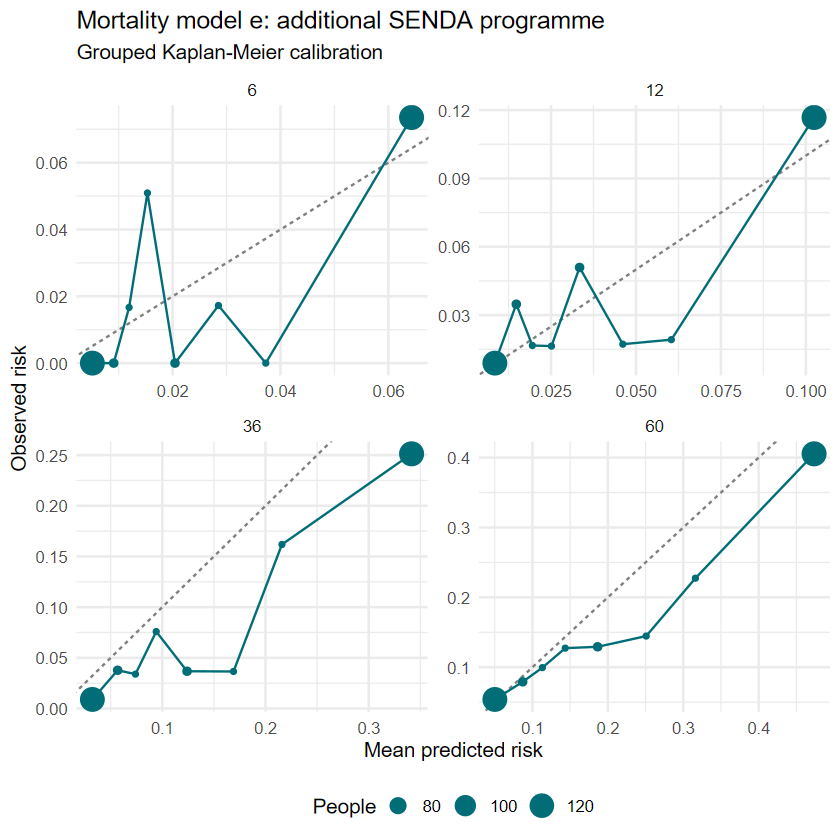

Elapsed: 0.007 minutes


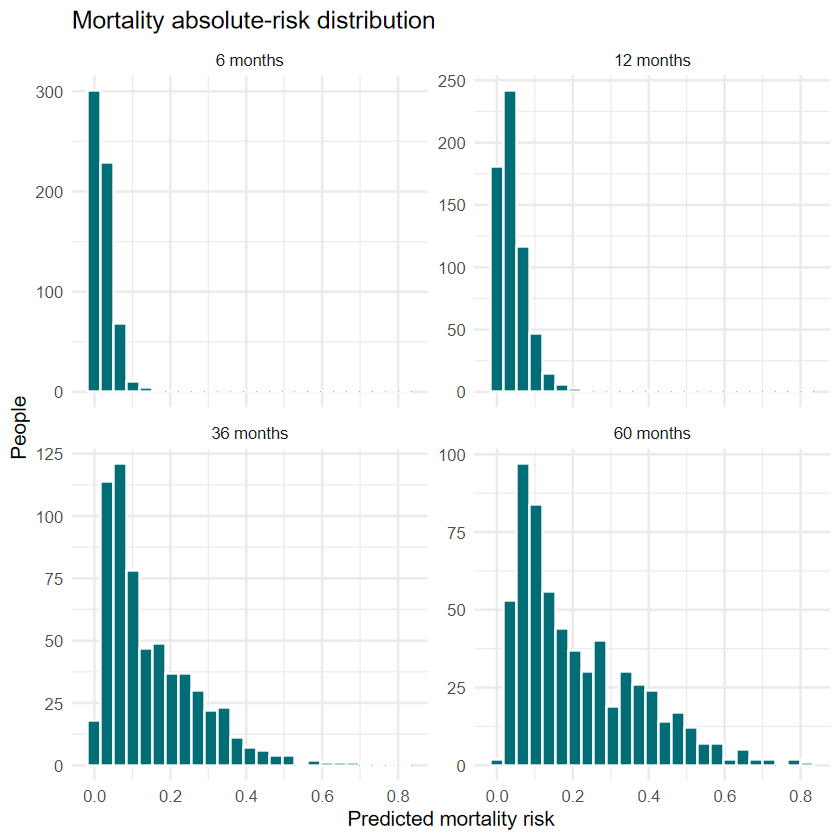

In [22]:
#| label: c3-calibration-and-risk-figures
#| message: false
#| fig-width: 9
#| fig-height: 6
.t0 <- proc.time()
# Display original calibration groups and absolute-risk distributions without exporting intermediates.
calibration_plot <- ggplot2::ggplot(c3_point$curves,ggplot2::aes(x=mean_predicted,y=observed))+ggplot2::geom_abline(slope=1,intercept=0,linetype=2,colour="grey50")+ggplot2::geom_line(colour="#006D77")+ggplot2::geom_point(ggplot2::aes(size=n_patients),colour="#006D77")+ggplot2::facet_wrap(~time_months,scales="free")+ggplot2::labs(title="Mortality model e: additional SENDA programme",subtitle="Grouped Kaplan-Meier calibration",x="Mean predicted risk",y="Observed risk",size="People")+ggplot2::theme_minimal(base_size=12)+ggplot2::theme(legend.position="bottom")
print(calibration_plot)
risk_long <- do.call(rbind,lapply(HORIZONS,function(h) data.frame(Horizon=paste(h,"months"),Risk=1-c3_predictions$survival[,match(h,GRID)])))
risk_long$Horizon <- factor(risk_long$Horizon,levels=paste(HORIZONS,"months"))
print(ggplot2::ggplot(risk_long,ggplot2::aes(x=Risk))+ggplot2::geom_histogram(bins=25,fill="#006D77",colour="white")+ggplot2::facet_wrap(~Horizon,scales="free_y")+ggplot2::labs(title="Mortality absolute-risk distribution",x="Predicted mortality risk",y="People")+ggplot2::theme_minimal(base_size=12))
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


In [23]:
#| label: c3-table4-old-new-checkpoint
#| message: false
.t0 <- proc.time()
# Export the manuscript-source rows and classify changes at their reported precision.
# Pin the transcribed Table 4 reference to the exact configured manuscript version.
stopifnot(all(c("manuscript","homeless_notebook") %in% names(cfg$sources)))
manuscript_source <- resolve(cfg$sources$manuscript)
stopifnot(file.exists(manuscript_source))
manuscript_sha256 <- digest::digest(file=manuscript_source,algo="sha256")
reference_manuscript_sha256 <- "3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a"
if(!identical(manuscript_sha256,reference_manuscript_sha256)) stop("The configured manuscript differs from the audited Table 4 source. Recheck its transcribed reference before exporting comparisons.",call.=FALSE)
result <- c3_point$metrics[c3_point$metrics$Metric %in% c("C","IBS","ICI","EO"),]
result$Key <- paste(result$Metric,result$Horizon,sep="_")
ci <- c3_bootstrap$intervals[match(result$Key,c3_bootstrap$intervals$Key),]
result$Lower <- ci$Lower
result$Upper <- ci$Upper
result$Valid_replicates <- ci$Valid_replicates
result$Model <- "e: SHAP mortality; treatment-setting and physical-comorbidity strata"
result$Population <- "Additional SENDA homelessness programme"
result$N_eligible <- nrow(c3$nondum)
result$N_evaluated <- nrow(c3_analysis_cohort)
result$Deaths_evaluated <- sum(c3_analysis_cohort$death_event)
result$Missing_discharge_policy <- missing_policy
result$Physical_rule <- physical_policy
comparison <- old_reference
idx <- match(paste(comparison$Metric,comparison$Horizon,sep="_"),result$Key)
stopifnot(!anyNA(idx))
comparison$New <- result$Value[idx]
comparison$New_lo <- result$Lower[idx]
comparison$New_hi <- result$Upper[idx]
comparison$Difference <- comparison$New-comparison$Previous
comparison$Current <- mapply(format_interval,comparison$New,comparison$New_lo,comparison$New_hi,comparison$Digits)
comparison$Classification <- ifelse(comparison$Current==comparison$Manuscript,"trivial","substantial")
comparison$Previous_population <- "605 historical complete cases; 71 deaths"
comparison$Current_population <- paste(nrow(c3_analysis_cohort),"evaluable people;",sum(c3_analysis_cohort$death_event),"deaths")
show_table(comparison[c("Horizon","Metric","Manuscript","Current","Difference","Classification")],"Table 4 checkpoint: published versus current frozen pipeline")
cat("Changes combine development preprocessing/model, predictor reconstruction, physical-stratum correction and availability. They do not isolate leakage bias.\n")
# Map every estimate and interval component to its producing cell and exported column.
metrics_filename <- paste0("Table4_C3_mortality_metrics_",run_date,"_",bootstrap_signature,".csv")
traceability <- do.call(rbind,lapply(seq_len(nrow(result)),function(i) {
  matched <- match(result$Key[i],paste(comparison$Metric,comparison$Horizon,sep="_"))
  stopifnot(!is.na(matched))
  data.frame(Manuscript_item="Table 4: case-mix all-cause mortality",Horizon_months=result$Horizon[i],Metric=result$Metric[i],Component=c("estimate","lower_95","upper_95"),Notebook=cfg$sources$homeless_notebook,Producer_cell=c("c3-table4-metric-engine","c3-table4-bootstrap","c3-table4-bootstrap"),Export_cell="c3-table4-old-new-checkpoint",Output_file=file.path(cfg$paths$tables,metrics_filename),Output_column=c("Value","Lower","Upper"),Manuscript_source_config="sources.manuscript",Manuscript_SHA256=manuscript_sha256,Reference="c3-historical-control: expected_word",Prediction_signature=prediction_signature,Bootstrap_signature=bootstrap_signature,Review_status=if(comparison$Classification[matched]=="substantial")"investigator_review_pending" else "reproduced_at_published_precision",row.names=NULL)
}))
stopifnot(nrow(traceability)==3L*nrow(result),all(traceability$Output_column %in% names(result)),!anyNA(traceability))
show_table(traceability,"Table 4 source mapping and configured manuscript fingerprint")
table_dir <- resolve(cfg$paths$tables)
for(item in c("metrics","comparison","cohort_accounting","traceability")) {
  value <- switch(item,metrics=result,comparison=comparison,cohort_accounting=c3_accounting,traceability=traceability)
  destination <- file.path(table_dir,paste0("Table4_C3_mortality_",item,"_",run_date,"_",bootstrap_signature,".csv"))
  if(file.exists(destination)) {
    existing <- utils::read.csv(destination,check.names=FALSE)
    stopifnot(isTRUE(all.equal(existing,value,check.attributes=FALSE)))
  } else {
    utils::write.csv(value,destination,row.names=FALSE,na="")
    written <- c(written,destination)
  }
}
review_signature <- substr(digest::digest(list(comparison,missing_policy,physical_policy),algo="sha256"),1L,12L)
cat("Investigator review signature:",review_signature,"\n")
cat("Changes are flagged for the combined 09-11 checkpoint. No manuscript edit or model decision is made here.\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Horizon,Metric,Manuscript,Current,Difference,Classification
6,C,"0.726 (0.603, 0.839)","0.746 (0.623, 0.870)",0.020595,substantial
6,IBS,"0.014 (0.007, 0.022)","0.014 (0.007, 0.022)",-0.000303,trivial
6,ICI,"0.010 (0.005, 0.024)","0.008 (0.006, 0.021)",-0.002136,substantial
6,EO,"0.59 (0.39, 1.09)","1.12 (0.73, 2.18)",0.534646,substantial
12,C,"0.721 (0.627, 0.821)","0.727 (0.626, 0.831)",0.006421,substantial
12,IBS,"0.022 (0.013, 0.032)","0.021 (0.013, 0.030)",-0.000492,substantial
12,ICI,"0.017 (0.008, 0.034)","0.009 (0.007, 0.025)",-0.008198,substantial
12,EO,"0.62 (0.44, 0.95)","1.03 (0.72, 1.58)",0.409311,substantial
36,C,"0.780 (0.722, 0.832)","0.773 (0.707, 0.837)",-0.006678,substantial
36,IBS,"0.048 (0.035, 0.061)","0.048 (0.037, 0.059)",0.000053,substantial


Changes combine development preprocessing/model, predictor reconstruction, physical-stratum correction and availability. They do not isolate leakage bias.


Manuscript_item,Horizon_months,Metric,Component,Notebook,Producer_cell,Export_cell,Output_file,Output_column,Manuscript_source_config,Manuscript_SHA256,Reference,Prediction_signature,Bootstrap_signature,Review_status
Table 4: case-mix all-cause mortality,6,C,estimate,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-metric-engine,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Value,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,investigator_review_pending
Table 4: case-mix all-cause mortality,6,C,lower_95,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-bootstrap,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Lower,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,investigator_review_pending
Table 4: case-mix all-cause mortality,6,C,upper_95,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-bootstrap,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Upper,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,investigator_review_pending
Table 4: case-mix all-cause mortality,6,IBS,estimate,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-metric-engine,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Value,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,reproduced_at_published_precision
Table 4: case-mix all-cause mortality,6,IBS,lower_95,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-bootstrap,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Lower,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,reproduced_at_published_precision
Table 4: case-mix all-cause mortality,6,IBS,upper_95,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-bootstrap,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Upper,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,reproduced_at_published_precision
Table 4: case-mix all-cause mortality,6,ICI,estimate,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-metric-engine,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Value,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,investigator_review_pending
Table 4: case-mix all-cause mortality,6,ICI,lower_95,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-bootstrap,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Lower,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,investigator_review_pending
Table 4: case-mix all-cause mortality,6,ICI,upper_95,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-bootstrap,c3-table4-old-new-checkpoint,outputs/tables/Table4_C3_mortality_metrics_2026-10-10_94d6f3bc6b4a.csv,Upper,sources.manuscript,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a,c3-historical-control: expected_word,a087a5033727,94d6f3bc6b4a,investigator_review_pending
Table 4: case-mix all-cause mortality,6,EO,estimate,notebooks/11_homeless_progr_death_int_val.ipynb,c3-table4-metric-engine,c3-table4-old-new

Investigator review signature: 0c7e4e8d9b8b 


Changes are flagged for the combined 09-11 checkpoint. No manuscript edit or model decision is made here.


Elapsed: 0.006 minutes


## Scope and limits
The adult C3 universe, original overlap exclusion, first-episode rule, not-alive-at-discharge rule, 0.23-month administrative-discharge rule and December 2020 follow-up cutoff are preserved. Missing predictions are never silently discarded. Any authorized five-person restriction is accounted for after eligibility.
Development-only imputation fitting, frozen application, encoding and model fitting are separate from this additional cohort. Internal development CV was not independent of full-development imputation. Housing tenure is wholly unmeasured in C3; several auxiliaries use the index-episode report rather than every original C1 longitudinal repair. The primary bootstrap reuses fixed predictions and imputations. The separate sensitivity also varies the two explicitly uncertain fields while other completed inputs and fitted parameters stay fixed. Complete preprocessing independence is not claimed.
The historical mortality model had 14 coefficients; current e has 25, with the same two stratification terms. No historical Full-model Table 4 result exists for C3. No DCA or classification thresholds were original outputs for these manuscript rows.
The original common-support and nearest-neighbour subsets had identical reported metrics to the full historical complete-case cohort. Their old results remain antecedents. New propensity matching, adolescent analysis, baseline recalibration and Brier-skill bootstrap are not run by this Table 4 port. They do not supply its four mortality rows; this scope reduction must be recorded in `docs/simplificaciones.md`. It does not imply that newly reconstructed inputs would yield identical matched subsets.


## Session info

In [24]:
#| label: c3-session-info
#| message: false
.t0 <- proc.time()
cat(sprintf("Notebook wall time: %.3f minutes\n",as.numeric(difftime(Sys.time(),execution_started,units="mins"))))
print(utils::sessionInfo())
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


Notebook wall time: 66.223 minutes


R version 4.4.1 (2024-06-14 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default


locale:
[1] LC_COLLATE=C                        LC_CTYPE=English_United States.utf8
[3] LC_MONETARY=C                       LC_NUMERIC=C                       
[5] LC_TIME=C                          

time zone: America/Santiago
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
  [1] tidyselect_1.2.1          IRdisplay_1.1            
  [3] dplyr_1.1.4               farver_2.1.2             
  [5] fastmap_1.2.0             TH.data_1.1-3            
  [7] janitor_2.2.1             digest_0.6.37            
  [9] rpart_4.1.23              timechange_0.3.0         
 [11] lifecycle_1.0.5           cluster_2.1.8.1          
 [13] Cairo_1.6-2               survival_3.6-4           
 [15] magrittr_2.0.3            compiler_4.4.1           
 

Elapsed: 0.004 minutes


## Written files

In [25]:
#| label: c3-written-files
#| message: false
.t0 <- proc.time()
files <- unique(written)
manifest <- data.frame(File=substring(files,nchar(root)+2L),Bytes=as.numeric(file.info(files)$size))
show_table(manifest,"Files written in outputs")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))


File,Bytes
outputs/objects/c3_sensitivity_completed_imp1_2026-10-10_b29d2f38db5d.rds,1651630
outputs/objects/c3_sensitivity_component_imp1_2026-10-10_b29d2f38db5d.rds,2231630
outputs/objects/c3_sensitivity_discharge_forest_imp2_2026-10-10_b3cf2f08d855.rds,208184522
outputs/objects/c3_sensitivity_completed_imp2_2026-10-10_b29d2f38db5d.rds,1651630
outputs/objects/c3_sensitivity_component_imp2_2026-10-10_b29d2f38db5d.rds,2231630
outputs/objects/c3_sensitivity_discharge_forest_imp3_2026-10-10_f69c15fbbd77.rds,208176202
outputs/objects/c3_sensitivity_completed_imp3_2026-10-10_b29d2f38db5d.rds,1651630
outputs/objects/c3_sensitivity_component_imp3_2026-10-10_b29d2f38db5d.rds,2231630
outputs/objects/c3_sensitivity_discharge_forest_imp4_2026-10-10_7fe56708ebde.rds,208224586
outputs/objects/c3_sensitivity_completed_imp4_2026-10-10_b29d2f38db5d.rds,1651630


Elapsed: 0.001 minutes
